# Baseline 6 — RIAD, WS2, shared 100-epoch policy

**Resume the timed-out run rather than repeating its 37 completed epochs.** The supplied compact
report contains no evaluated test results. This notebook imports the saved epoch checkpoint under
the shared **maximum 100 epochs / validation every epoch / normal-only patience 10** policy.
The constant learning rate permits continuation: the previous 300-epoch cap never affected its
optimizer schedule. The importer verifies every other recipe field and replays the stopping rule
over the existing validation history. It refuses an incompatible or already overtrained trajectory.

**Inputs:** attach the same WS2 dataset and the complete old Baseline 6 Kaggle output containing
`config.json`, `best.pt` and `last.pt`. A compact report ZIP alone cannot resume training.
Enable a Kaggle GPU. No Internet or package download is required. Set `SAVED_RUN_DIR` only if more
than one matching output is attached. Optional four dataset path overrides are in the first cell.

**Run sequence:**
1. First session: leave `MODE='import_legacy100'`, attach the original 300-cap output, run all cells.
2. If paused: retain the entire new output, attach it in the next session, set `MODE='resume100'`.
   Resume from the newest output, not the original epoch-37 folder.
3. Training automatically evaluates only after reaching epoch 100 or the normal stopping rule.
   `MODE='evaluate_completed'` can resume evaluation of a completed new-policy run.
4. `MODE='new100'` is an explicit fresh-run alternative when exact Adam/checkpoints are unavailable.
   It uses a new output directory and refuses to overwrite existing work.

At the observed ~19 minutes/epoch, 63 additional epochs are roughly **20 GPU hours**, plus scoring;
early stopping can reduce this but is not guaranteed. The notebook uses GPU 0 only. T4×2 does not
halve runtime. Naive two-GPU DataParallel would change batch-normalization behavior, so it is not
introduced. The 9-hour guard and periodic atomic checkpoints allow multiple Kaggle sessions.
Hard kills can lose at most the interval since the last saved batch checkpoint; those updates are
replayed with their saved cursor and RNG. Training never reports unfinished epochs as completed.

## Method and source fidelity
The network is a **28,805,699-parameter U-Net** from the pinned third-party MIT
[RIAD implementation](https://github.com/taikiinoue45/RIAD/tree/36139f9f8fb9092e72fc9f51e8871535276c1f68).
It is **not verified original author code**. The embedded U-Net, SSIM and MSGMS definitions remain
byte-for-byte identical to the previous baseline notebook. The source recipe normalizes RGB to
[-1,1], hides complementary patches, reconstructs only hidden pixels and optimizes MSE + SSIM + MSGMS.
All training images are normal. There are no pretrained encoder weights and no supervised anomaly labels.

`shared_mae` measures RGB difference from the mean reconstruction over four mask sizes;
`riad_msgms` is the native gradient-structure discrepancy. Both are fixed in advance and reported.
The comparison uses the exact inherited split (3,829 / 521 / 128 / 234 / 496), 256-pixel geometry,
threshold protocols and morphology. Historical thresholding uses all normal validation pixels;
the independent protocol calibrates on its calibration subset and reports achieved audit FPR.
Test labels are decoded only after checkpoint and threshold locking.

## What the added blocks achieve
- **Verified migration:** saves old checkpoint SHA lineage and carries Adam state forward.
- **Early stopping:** meaningful improvement resets the patience counter; the absolute best normal
  objective independently selects the checkpoint, even for smaller improvements.
- **Partial resume:** saves model, Adam, batch cursor, accumulated losses and training RNG.
- **Uniform report:** mean foreground frame IoU, frame Dice/precision/recall, pooled metrics,
  full-pixel AP/AUROC/AUPRO and training budget metadata. `mean_iou` aliases foreground frame IoU;
  it is not the conventional mean of foreground and background class IoU.

**Send back:** `RIAD_baseline_6_100cap_report.zip` and the execution log. The report excludes `.pt`
and `.npy`; retain the full output yourself for continuation. Send a paused report as a status update,
but its absence of test metrics is intentional. No test label is used for early stopping or model choice.

In [1]:
import os, sys, json, time, random, hashlib, shutil, zipfile, base64, zlib
from pathlib import Path
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
import numpy as np
import pandas as pd
from PIL import Image
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from scipy.ndimage import (gaussian_filter, generate_binary_structure,
    binary_closing, binary_opening, binary_fill_holes, label)
from sklearn.metrics import average_precision_score, roc_auc_score
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display, FileLink

# User settings — recovery only; this notebook never starts a new model training run.
SESSION_START = time.monotonic()
MODE = 'resume100'  # import_legacy100 / resume100 / new100 / evaluate_completed
SAVED_RUN_DIR = ""                   # folder with config.json, best.pt, last.pt
SESSION_BUDGET_HOURS = 10.0           # conservative guard for your observed 12-hour session
CHECKPOINT_RESERVE_SECONDS = 180.0
SCORE_FLUSH_EVERY = 16
if MODE not in {'import_legacy100','resume100','new100','evaluate_completed'}: raise ValueError(MODE)
if not 0.25 <= SESSION_BUDGET_HOURS <= 10.0:
    raise ValueError('Keep the planned budget between 0.25 and 10 hours.')
DEADLINE = SESSION_START + SESSION_BUDGET_HOURS*3600
INPUT = Path('/kaggle/input')
RUN = Path('/kaggle/working/RIAD_baseline_6_100cap')
# Normally leave blank. If multiple copies of WS2 are attached, set all four.
TRAIN_ROOT_OVERRIDE = ''
VAL_ROOT_OVERRIDE = ''
TEST_ROOT_OVERRIDE = ''
MASK_ROOT_OVERRIDE = ''
# Native recipe is unchanged; the shared cap/stopping policy below is new.
SEED = 1337
EPOCHS = 100
PATIENCE = 10
STOP_MIN_RELATIVE = .001
STOP_ABS_FLOOR = 1e-8
SAVE_EVERY_BATCHES = 50
CUTOUTS = (2,4,8,16)
BATCH = 4
WORKERS = 2
SIZE = 256
LR, WEIGHT_DECAY = 1e-4, 1e-5
VALIDATE_EVERY = 1
FPRS = (0.005, 0.01, 0.02, 0.05, 0.10)
SCORES = ('shared_mae', 'riad_msgms')
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if DEVICE.type != 'cuda':
    raise RuntimeError('Enable a Kaggle GPU before running this full experiment.')
torch.set_num_threads(min(4, os.cpu_count() or 1))
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)
seed_all(SEED)

def digest(obj):
    return hashlib.sha256(json.dumps(obj, sort_keys=True).encode()).hexdigest()
def sha(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for b in iter(lambda: f.read(1024*1024), b''): h.update(b)
    return h.hexdigest()
def write_json(path, obj):
    path = Path(path); tmp = path.with_name(path.name+'.tmp')
    tmp.write_text(json.dumps(obj, indent=2, allow_nan=False)); tmp.replace(path)
def save_pt(obj, path):
    path = Path(path); tmp = path.with_name(path.name+'.tmp')
    torch.save(obj, tmp); tmp.replace(path)
def load_pt(path):
    return torch.load(path, map_location='cpu', weights_only=True)

def report_zip():
    destination = Path('/kaggle/working/RIAD_baseline_6_100cap_report.zip')
    with zipfile.ZipFile(destination, 'w', zipfile.ZIP_DEFLATED) as z:
        for p in sorted(RUN.rglob('*')):
            if p.is_file() and '_cache' not in p.relative_to(RUN).parts and p.suffix in {'.json','.csv','.png','.txt','.py'}:
                z.write(p, p.relative_to(RUN))
    return destination
class SessionBudgetPause(RuntimeError): pass

def budget_check(needed_seconds=120, reason='safe session pause'):
    if time.monotonic()+needed_seconds < DEADLINE: return
    write_json(RUN/'status.json', dict(status='paused', stage=reason,
        mode=MODE, elapsed_hours=(time.monotonic()-SESSION_START)/3600,
        next_action='Attach this full output in a new session; use the same mode.'))
    report_zip()
    raise SessionBudgetPause(reason)

def discover_saved_run():
    if MODE=='new100':
        if RUN.exists() and any(RUN.iterdir()):
            raise RuntimeError('The new output directory already contains a run. Use resume100, or move the old directory first.')
        return None
    if SAVED_RUN_DIR:
        p=Path(SAVED_RUN_DIR)
        if not p.is_dir():raise FileNotFoundError(p)
        return p
    if MODE!='import_legacy100' and all((RUN/n).is_file() for n in ('config.json','best.pt','last.pt')):
        return RUN
    candidates=[]
    for p in INPUT.rglob('config.json'):
        try:c=json.loads(p.read_text())
        except (ValueError,OSError):continue
        if c.get('implementation')!='RIAD_taikiinoue45_WS2_v1':continue
        is_new=c.get('benchmark_policy')=='100cap_normal_patience10_v1'
        if (MODE=='import_legacy100' and is_new) or (MODE!='import_legacy100' and not is_new):continue
        if all((p.parent/n).is_file() for n in ('best.pt','last.pt')):candidates.append(p.parent)
    if len(candidates)!=1:
        raise RuntimeError('Attach the complete RIAD output with config.json, best.pt and last.pt. '
            'The report ZIP excludes weights. Set SAVED_RUN_DIR if multiple compatible outputs are attached. Found: '+str(candidates))
    return candidates[0]

SOURCE_RUN=discover_saved_run()
if SOURCE_RUN is not None:
    for name in ('config.json','best.pt','last.pt'):
        if not (SOURCE_RUN/name).is_file():raise FileNotFoundError(SOURCE_RUN/name)
print('Mode:',MODE,'| source run:',SOURCE_RUN)
print('Using only GPU 0:',torch.cuda.get_device_name(0),'| visible GPUs:',torch.cuda.device_count())
print('100-epoch maximum, normal-only patience 10; session budget:',SESSION_BUDGET_HOURS,'hours')


Mode: resume100 | source run: /kaggle/input/models/shuvroahmedimaging/riadoldv2/pytorch/default/1
Using only GPU 0: Tesla T4 | visible GPUs: 2
100-epoch maximum, normal-only patience 10; session budget: 10.0 hours


## 1. Verify the dataset and checkpoint recipe
This block hashes image content and checks exact record order and disjoint video subsets. A legacy
import may change the epoch cap, stopping rule and reporting metadata; it may not change the network,
loss, mask sampling, optimizer, learning rate, precision, source revision or dataset.

In [2]:
# Exact record order from qmem_experiment8/20260921_202543_2328f4/splits.json
REFERENCE = json.loads(zlib.decompress(base64.b64decode('eNqt3c2uLUt2mNd3uW1KPvMnfpKvQhBGSSoaNGhLKJXVEfTuKghuidDOeZSjV8DdGDhAfZErc8WMXP/1j7/+5U///P/+8ff/8F//+Muf/+VPf/3n//LnP/7+jz/901///Jd/81/++T/8+T/+m1+/fv0f//SXP/0/f/4///a/4t/+3//p//rj7/74H//pX//hH//t72ZOIqeQ08hZyNnIOci5yHmME7+Q86nnmK6LGDuJnEJOI2chZyPnIOci5zHOy7qYO596zum6yLGTyCnkNHIWcjZyDnIuch7jvKyLuYN6DtRzoJ4D9Ryo50A9B+o5UM+Bek7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOinutTzzW936ixk8gp5DRyFnI2cg5yLnKeL05PO+yxk8gp5DRyFnI2cg5yLnIe47zc9744a9rzGjuJnEJOI2chZyPnIOci5zHOS89zB/UcqOdAPQfqOVDPgXoO1HOgngP1nKjnRD0n6jlRz4l6TtRzop4T9Zyo50Q9F+q5UM+Fei7Uc6GeC/VcqOdCPRfquVDPjXpu1HOjnhv13KjnRj036rlRz416btTzQj0v1PP61POePp/usZPIKeQ0chZyNnIOci5yHuO8PJ++OGfa8xk7iZxCTiNnIWcj5yDnIucxzkvPcwf1HKjnQD0H6jlQz4F6DtRzoJ4D9Zyo50Q9J+o5Uc+Jek7Uc6KeE/WcqOdEPRfquVDPhXou1HOhnutTz3d6X3fHTiKnkNPIWcjZyDlfnGf6//szdhI5hZxGzkLORs5BzkXOY5yX+/m5g3oO1HOgngP1HKjnQD0H6jlQz4F6TtRzop4T9Zyo50Q9J+o5v/Qc03OI8WvsJHIKOY2chZyNnPPFmZ6zixg7iZxCTiNnIWcj5yDnIucxzs/3Ub/hfOp5es4ucuwkcgo5jZyFnI2cg5yLnMc4L+ti7qCeA/UcqOdAPQfqOVDPgXoO1HOgnhP1nKjnRD0n6jlRz4l6TtRzop4T9Zyo50I9F+q5UM+Fei7Uc6GeC/VcqOdCPRfquVHPjXpu1HN/6nl6HjZq7CRyCjmNnIWcjZyDnIucxzgvzwVz51PP0/O50WMnkVPIaeQs5GzknC/O9BxrrLGTyCnkNHIWcjZyDnIucp4vznRePfbYSeQUcho5CzkbOQc5FzmPcV4+l+cO6jlQz4F6DtRzoJ4D9Ryo50A9B+o5Uc+Jek7Uc6KeE/WcqOdEPSfqOVHPiXou1HOhngv1XKjnQj0X6rlQz4V6LtRzoZ4b9dyfep6es4szdhI5hZxGzkLORs5BzkXO88WZnguIO3YSOYWcRs5CzkbOQc5FzmOcl+fBuYN6DtRzoJ7jU8/T8yDxjJ1ETiGnkbOQs5FzkHOR8xjnZb3PnS8953SuO3+NnUROIaeRs5CzkXOQc5HzGOfndfEbDuo5UM+Beg7Uc6CeA/UcqOdAPcennqfnJjLGTiKnkNPIWcjZyDnIuch5jPNyXZ07n3qenpvIHDuJnEJOI2chZyPnIOci5zHOy7qYO6jnQD0H6jlQz4F6DtRzoJ4D9Ryo50Q9J+o5Uc+Jek7Uc6KeE/WcqOdEPSfquVDPhXou1HOhngv1XKjnQj0X6rlQz4V6btRzf+p5ek4ha+wkcgo5jZyFnI2cg5yLnMc4L/fhcwf1HKjnQD0H6jlQz4F6DtRzoJ4D9Zyo50Q9J+o5Uc+Jek7Uc6KeE/WcqOdEPRfquVDPhXou1HOhngv1XKjnQj3Xp56n5wezx04ip5DTyFnI2cg5yLnIeYzzcr86dz71PD1fmWvsJHIKOY2chZyNnIOci5zHOC/rYu6gngP1HKjnQD0H6jlQz4F6DtRzoJ4T9Zyo50Q9J+o5Uc+Jek7Uc6KeE/WcqOdCPRfquVDPhXou1HOhngv1XKjnQj0X6rlRz416btRzo54b9dyo50Y9N+q5Uc+Nel6o54V6Xp96nr53JffYSeQUcho5CzkbOeeLMz3nm2fsJHIKOY2chZyNnIOci5zHOC/fS7w40/PCecdOIqeQ08hZyNnIOci5yHmM89Lz3PnU8/RcbT5jJ5FTyGnkLORs5JwPTk3PjdavsZPIKeQ0chZyNnIOci5yHuP8fD18c6bn9SrGTiKnkNPIWcjZyDnIuch5jPPS89xBPQfqOVDPgXoO1HOgngP1HKjnQD0n6jlRz4l6TtRzop4T9Zyo50Q9J+o5Uc+Fei7Uc6GeC/VcqOdCPRfquVDPhXou1HOjnhv13KjnRj036rlRz416btRzo54b9bxQzwv1vD71PH1vRuXYSeQUcho5CzkbOeeLMz2nWTV2EjmFnEbOQs5GzkHORc7zxZmev6geO4mcQk4jZyFnI+cg5yLnMc7L92NzB/UcqOdAPcennqfnSmqNnUROIaeRs5CzkXOQc5HzGOdlvc8d1HOgngP1HJ96ns7p1R47iZxCTiNnIWcj5yDnIucxzst6nzufep7OMdYZO4mcQk4jZyFnI+cg5yLnMc7Lupg7n3qezkPWHTuJnEJOI2chZyPnIOci5zHOy7p4caZzjPWMnUROIaeRs5CzkXOQc5HzGOel57mDeg7Uc6CeA/UcX3ru6Rxs/xo7iZxCTiNnIWcj53xxpvOiHWMnkVPIaeQs5GzknC/OdB+2c+wkcgo5jZyFnI2cg5yLnMc4P98nvDnT/eWusZPIKeQ0chZyNnIOcu4XZ7ov3D12EjmFnEbOQs5GzkHORc5jnJfr4Ysz3ffsNXYSOYWcRs5CzkbOQc5FzmOcl55fnOm+Xu+xk8gp5DRyFnI2cg5yLnKeL850H63P2EnkFHIaOQs5GzkHORc5j3FerqtzB/UcqOdAPQfqOVDPgXoO1HOgngP1nJ96nu7n9h07iZxCTiNnIWcj5yDnIucxzsv1ee6gnuNTz9P95X7GTiKnkNPIWcjZyDnIuch5jPOyvn521nTfc/0aO4mcQk4jZyFnI+cg5yLnMc7PPb850/3cFWMnkVPIaeQs5GzkHOTcL850X3jl2EnkFHIaOQs5GzkHORc5j3FerodzB/UcqOf41PN0v3vV2EnkFHIaOQs5GzkHORc5zxdnum++euwkcgo5jZyFnI2cg5z7xZnuU681dhI5hZxGzkLORs5BzkXO88WZ7i+vPXYSOYWcRs5CzkbOQc5FzmOcl/veuYN6DtRzoJ4D9Ryo50A9B+o5UM+Bek7Uc6Ke81PP0zmQdcZOIqeQ08hZyNnIOci5yHmM8/J58eJM983XHTuJnEJOI2chZyPnIOci5zHOS89zB/UcqOdAPQfqOVDPgXoO1HOgngP1nKjnRD0n6jlRz4l6TtRzop4T9Zyo50Q9F+q5UM+Fei7Uc6GeC/VcqOf61PN0fmw9YyeRU8hp5CzkbOScD86ezlntX2MnkVPIaeQs5GzkHORc5DzG+fn54jcc1HOgngP1HKjnQD0H6jlQz4F6DtRzop4T9Zyo50Q9J+o5Uc+Jek7Uc6KeE/VcqOdCPRfquVDPhXou1HOhngv1XKjn+tTzdB57x9hJ5BRyGjkLORs5BzkXOY9xXu575w7qOVDPgXoO1HOgngP1HJ96np4L2Dl2EjmFnEbOQs5GzkHORc7zxZnOve8aO4mcQk4jZyFnI+cg5yLnMc7L5+ncQT0H6jlQz/Gp5+n5gt1jJ5FTyGnkLORs5BzkXOQ8xnlZ7y/O9LzDXmMnkVPIaeQs5GzkHORc5DzGeen5xZmem9h77CRyCjmNnIWcjZyDnIucxzgvPc8d1HN86nk6Z77P2EnkFHIaOQs5GzkHORc5j3Fe1teLM50z33fsJHIKOY2chZyNnPPFmc597WfsJHIKOY2chZyNnIOci5zHOC/XsbnzpecznYs7v8ZOIqeQ08hZyNnIOci5yHm+ONN96hNjJ5FTyGnkLORs5BzkXOQ8X5zpPuPJsZPIKeQ0chZyNnIOci5yHuP8fJ/w5kz3K0+NnUROIaeRs5CzkXOQc5HzGOel57mDeo5PPU/3B0+PnUROIaeRs5CzkXOQc5HzGOdlfc0d1HOgnuNTz9N9z7PGTiKnkNPIWcjZyDnIuch5jPOyTufOp56n+6dnj51ETiGnkbOQs5FzkHOR8xjnZV3MHdRzoJ4D9Ryo50A9B+o5UM+Beg7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOinhP1XKjnQj0X6rlQz4V6LtRzoZ4L9Vyo5/rU83Su6Zyxk8gp5DRyFnI2cg5yLnKeL850HuncsZPIKeQ0chZyNnIOcu4XZzrXdJ6xk8gp5DRyFnI2cg5yLnIe47w8v//s3Ok80v01dhI5hZxGzkLORs5BzkXOY5yfe/4NB/UcqOdAPQfqOVDPgXoO1HOgngP1nKjnRD0n6jlRz4l6TtRzop4T9Zyo50Q9F+q5UM+Fei7Uc6GeC/VcqOdCPRfquVDPjXpu1HOjnhv13KjnRj036rlRz416btTzQj0v1PNCPS/U80I9L9TzQj0v1PNCPa9PPU/Pp9wYO4mcQk4jZyFnI+d8cabnQW6OnUROIaeRs5CzkXOQc5HzfHGm5zhujZ1ETiGnkbOQs5FzkHOR83xxpucdbo+dRE4hp5GzkLORc5BzkfN8cabz/HeNnUROIaeRs5CzkXOQc5HzGOdln2juoJ4D9Ryo50A9B+o5UM+Beg7Uc6CeE/WcqOdEPSfqOVHPiXpO1HN+6nl6nujusZPIKeQ0chZyNnIOci5yni/OdL73nrGTyCnkNHIWcjZyDnIuch7jvNwfzh3Uc6CeA/UcqOdAPQfqOVDPgXoO1HOinhP1nKjnRD0n6jlRz4l6zk89T8873Dt2EjmFnEbOQs5GzkHORc5jnJfP5bmDeg7Uc6CeA/UcqOdAPQfqOVDPgXpO1HOinhP1nKjnRD0n6jlRz4l6TtRzfup5eq7tPmMnkVPIaeQs5GzknA/OMz3/9fwaO4mcQk4jZyFnI+cg5yLn+eJM5/2eGDuJnEJOI2chZyPnIOci5zHOz88pv+GgngP1HKjnQD0H6jk+9TydO31y7CRyCjmNnIWcjZyDnIucxzgv15+5g3oO1HOgngP1HKjnQD0H6jlQz4F6TtRzop4T9Zyo5/zU83Re/amxk8gp5DRyFnI2cg5yLnIe47x8fs0d1HOgngP1HKjnQD0H6jlQz4F6DtRzop4T9Zyo5/zU8/R8ytNjJ5FTyGnkLORs5BzkXOQ8X5zp+ZRnjZ1ETiGnkbOQs5FzkHOR8xjn5f5n7qCeA/UcqOdAPQfqOVDPgXoO1HOgnhP1nKjnRD0n6jlRz4l6zk89T8+VPHvsJHIKOY2chZyNnIOci5zHOC+fp3MH9Ryo50A9B+o5UM+Beg7Uc6CeA/WcqOdEPSfqOVHPiXpO1HOinhP1nKjnRD0X6rlQz4V6LtRzoZ4L9Vyo5/rU8/Tc6HPGTiKnkNPIWcjZyDnIuch5vjjTc1LPHTuJnEJOI2chZyPnIOci5zHOy/PO3PnU8/RcwPOMnUROIaeRs5CzkXOQc//3nfg1PF/wtz8cO4mcQk4jZyFnI+cg5yLnMc6P19XfcVDPgXoO1HOgngP1HJ96jun1J8ZOIqeQ08hZyNnIOci5yHm+ODntMMdOIqeQ08hZyNnIOci5yHmM8/I5OHc+9VzTdVFjJ5FTyGnkLORs5BzkXOQ8xnlZF3PnU889XRc9dhI5hZxGzkLORs5BzkXOY5yXdTF3UM+Beg7Uc6CeA/UcqOdAPQfqOVDPiXpO1HOinhP1nKjnRD0n6jlRz4l6TtRzoZ4L9Vyo50I9F+q5UM+Fei7Uc6GeC/XcqOdGPTfquVHPjXruTz2v6XPKGjuJnEJOI2chZyPnIOci5zHOy3PK3EE9B+o5PvW8p+t0j51ETiGnkbOQs5FzkHOR8xjnZZ3OnU89n+m6OGMnkVPIaeQs5GzkHORc5DzGeVkXcwf1HKjnQD0H6jlQz4F6DtRzfOr5Tq+Hd+wkcgo5jZyFnI2cg5yLnMc4L9fDufOp52e6Lp6xk8gp5DRyFnI2cg5yLnIe47ysi7mDeg7Uc6CeA/UcqOdAPQfqOVDPgXpO1HOinhP1nKjnRD0n6jlRz4l6TtRzop4L9Vyo50I9F+q5UM+Fei7Uc6GeC/VcqOdGPTfquVHPjXpu1HOjnhv13KjnRj036nmhnhfqeaGeF+p5oZ4X6nmhnhfqeaGeF+p5o5436nmjnjfqeaOeN+p5o5436nmjnjfq+aCeD+r5oJ4P6vmgng/q+aCeD+r5oJ4P6vmini/q+aKeL+r5op4v6vminu+XnmP6/oT4NXYSOYWcRs5CzkbOQc5FzvPFmZ6jjxg7iZxCTiNnIWcj5yDnIucxzs/7X7/hoJ7jU8/T9wNEjp1ETiGnkbOQs5FzkHOR8xjnZX3NHdRzoJ4D9Ryo50A9B+o5UM+Beg7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOinhP1XKjnQj0X6rlQz4V6LtRzoZ4L9Vyo5/rU8/T9P1FjJ5FTyGnkLORs5BzkXOQ8X5zp+3aix04ip5DTyFnI2cg5yLnIeYzz8vw1d1DPgXoO1HOgngP1HKjnQD0H6jlQz4l6TtRzop4T9Zyo50Q9J+o5Uc+Jek7Uc6GeC/Vcn3qevscj1thJ5BRyGjkLORs554szfS9E7LGTyCnkNHIWcjZyDnIuch7jvNz3vjjT9znEGTuJnEJOI2chZyPnIOci5/niTM/Rxx07iZxCTiNnIWcj5yDnIucxzst1de6gngP1HKjnQD0H6jk+9Tx9X0E8YyeRU8hp5CzkbOQc5FzkPB+cnM6v5q+xk8gp5DRyFnI2cg5yLnIe4/z8OfgbDuo5UM+Beo5PPU/nhDPGTiKnkNPIWcjZyDnIuch5jPOy3ufOp56n872ZYyeRU8hp5CzkbOQc5FzkPMZ5WRdzB/UcqOdAPQfqOVDP8ann6ZxV1thJ5BRyGjkLORs5BzkXOc8XZzpnlT12EjmFnEbOQs5GzkHORc5jnJfPwbnzqefp/nuusZPIKeQ0chZyNnIOci5yHuO8rIu5g3oO1HOgngP1HKjn+NTzdA4k99hJ5BRyGjkLORs5BzkXOY9xXq4/cwf1HKjnQD0H6jk+9Tydt8kzdhI5hZxGzkLORs5BzkXOY5yX68bcQT0H6jlQz4F6DtRzoJ4D9Ryo50A9J+o5Uc+Jek7Uc6Ke81PP03m/vGMnkVPIaeQs5GzkHORc5DzGefkcfHGm82P5jJ1ETiGnkbOQs5FzkHOR8xjnpee5g3oO1HOgngP1HKjnQD0H6jlQz4F6TtRzop4T9Zyo50Q9J+o5Uc+Jek7Uc6KeC/VcqOdCPRfquVDP9aXnms5j16+xk8gp5DRyFnI2cg5yLnIe4/x8X/cbDuo5UM+Beg7Uc6CeA/UcqOdAPQfqOVHPiXpO1HOinvNTz9PzBRVjJ5FTyGnkLORs5BzkXOQ8xnn5/Jo7n3qeni+oHDuJnEJOI2chZyPnIOci5zHOy7qYO6jn+NTzdH6+auwkcgo5jZyFnI2c88WZzqtXj51ETiGnkbOQs5FzvjjTeexaYyeRU8hp5CzkbOQc5FzkPF+c6Vxu7bGTyCnkNHIWcjZyDnIuch7jvNzXzR3Uc3zqeTq/WmfsJHIKOY2chZyNnIOci5zHOC/ra+6gnuNTz9O5uLpjJ5FTyGnkLORs5BzkXOQ8xnlZX3MH9Ryo50A9B+o5UM+Beg7Uc6CeA/WcqOdEPSfqOVHPiXpO1HOinhP1nKjnRD0X6rlQz4V6LtRzoZ4L9Vyo50I9F+q5UM+Nem7Uc6OeG/XcqOdGPTfquVHPjXpu1PNCPS/U80I9L9TzQj0v1PNCPS/U80I9L9TzRj1v1PNGPW/U80Y9b9TzRj1v1PNGPW/U80E9H9TzQT0f1PP51PP0XGQ9YyeRU8hp5CzkbOQc5FzkPMZ5+T5z7qCeA/UcqOdAPQfqOVDPgXoO1HOgnvNLzz0939S/xk4ip5DTyFnI2cg5yLnIeb4403MKHWMnkVPIaeQs5GzkHORc5DzG+fk+4Tcc1HOgngP1HKjnQD0H6jlQz4F6DtRzop4T9Zyo50Q9J+o5Uc+Jek7Uc6KeE/VcqOdCPRfquVDPhXou1HOhngv1XKjnQj036rlRz416btRzo54b9dyo50Y9N+q5Uc8L9bxQzwv1vFDPC/W8UM8L9bxQzwv1vFDPG/W8Uc8b9bxRz/tTz9Pz+J1jJ5FTyGnkLORs5BzkXOQ8xnn5/ufFmZ5/7xo7iZxCTiNnIWcj5yDnIucxzkvPL870XH/32EnkFHIaOQs5GznnizM9199r7CRyCjmNnIWcjZyDnIucxzgv17G586nn6XsGeo+dRE4hp5GzkLORc5BzkfMY52VdzJ1PPU/fD9Bn7CRyCjmNnIWcjZyDnIucxzgv62LufOp5eq6/79hJ5BRyGjkLORs5Bzn3izOdo+5n7CRyCjmNnIWcjZyDnIucxzgv19WfnTWdO12/xk4ip5DTyFnI2cg5yLlfnOm86Iqxk8gp5DRyFnI2cg5yLnIe4/x8PfwN51PP0320lWMnkVPIaeQs5GzkHORc5DzGeVkXL850H23V2EnkFHIaOQs5GzkHORc5j3Feep47qOf41PN0X2/12EnkFHIaOQs5GzkHOfeLM90fXGvsJHIKOY2chZyNnIOci5zHOC/X57nzqefp/uDaYyeRU8hp5CzkbOQc5NwvznQfbZ2xk8gp5DRyFnI2cg5yLnIe47xcV+cO6jlQz4F6DtRzoJ4D9Ryo50A9B+o5Uc+Jek7Uc37qebpPve7YSeQUcho5CzkbOQc5FznPF2e6372esZPIKeQ0chZyNnIOcu4HZ0/3l/evsZPIKeQ0chZyNnIOci5yni/OdJ96x9hJ5BRyGjkLORs5BzkXOY9xfn6O+w0H9Ryo50A9B+o5UM+Beg7Uc6CeA/WcqOdEPSfqOVHPiXpO1HOinhP1nKjnRD0X6rlQz4V6LtRzoZ4L9Vyo50I916eep/NjO8dOIqeQ08hZyNnIOci5yHm+ONO5r11jJ5FTyGnkLORs5BzkXOQ8xnl5bpo7qOdAPcennqfzY7vHTiKnkNPIWcjZyDnIuch5jPOyTufOp56nc3F7jZ1ETiGnkbOQs5FzkHOR8xjnZV3MHdRzoJ4D9Ryo50A9B+o5UM+Beg7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOinhP1XKjnQj0X6rlQz/Wp5+k89t5jJ5FTyGnkLORs5BzkXOQ8X5zpXPc+YyeRU8hp5CzkbOQc5FzkPF+c6ZznvmMnkVPIaeQs5GzkHORc5DzGeXk+nTuo50A9B+o5UM+Beg7Uc6CeA/UcqOdEPSfqOT/1PJ3H3s/YSeQUcho5CzkbOQc5FzmPcV4+L352znQ+/PwaO4mcQk4jZyFnI+cg5yLn+eJM58NPjJ1ETiGnkbOQs5FzkHOR8xjn5+vqbzifep7OoZ0cO4mcQk4jZyFnI+cg5yLnMc7Lupg7qOdAPQfqOVDPgXoO1HOgnuNTz9N5yFNjJ5FTyGnkLORs5BzkXOQ8xnm5Hr4407nB02MnkVPIaeQs5GzkHORc5DzGeel57qCe41PP0/nDs8ZOIqeQ08hZyNnIOV+c6ZzD2WMnkVPIaeQs5GzkHORc5DzGebmuzh3Uc6Ce41PP0zmQc8ZOIqeQ08hZyNnIOci5yHmM87JOX5zpPMm5YyeRU8hp5CzkbOQc5FzkPMZ56XnufOp5um9+nrGTyCnkNHIWcjZyDnIuch7jvKyLuYN6DtRzoJ4D9Rxfer7T+YT7a+wkcgo5jZyFnI2cg5yLnMc4P183fsNBPQfqOVDPgXoO1HOgngP1HKjnQD3np56nczs3xk4ip5DTyFnI2cg5yLnIeb440zmZm2MnkVPIaeQs5GzkHOTcL850ruDW2EnkFHIaOQs5GznnizPdf789dhI5hZxGzkLORs5BzkXOY5yX54u586nn6b75XWMnkVPIaeQs5GzkHORc5DzGeVkXcwf1HJ96ns4n3D12EjmFnEbOQs5GzkHORc7zxZnuv98zdhI5hZxGzkLORs5BzkXOY5yX6/zcQT0H6jlQz4F6DtRzoJ4D9Ryo50A9J+o5Uc+Jek7Uc6KeE/WcqOdEPSfqOVHP9ann6XzUvWMnkVPIaeQs5GzkHORc5DzGebnfmDuo50A9B+o5UM+Beg7Uc6Ce41PP07m4+4ydRE4hp5GzkLORc5BzkfMY5+V6OHe+9PxM576eX2MnkVPIaeQs5GzkHORc5DzG+Xld/IbzqefpvM0TYyeRU8hp5CzkbOQc5FzkPF+c6bzNk2MnkVPIaeQs5GzkHORc5DzGebk+zx3Uc6CeA/UcqOdAPcennqfzWk+NnUROIaeRs5CzkXO+ONN5rafHTiKnkNPIWcjZyDnIuch5vjjT+ahnjZ1ETiGnkbOQs5FzkHOR83xxpnNEzx47iZxCTiNnIWcj5yDnIucxzst9+NxBPcennqfzUc8ZO4mcQk4jZyFnI+cg5yLnMc7L+po7qOdAPQfqOVDPgXoO1HOgngP1HKjnRD0n6jk/9Tydb3nu2EnkFHIaOQs5GzkHORc5j3FePi/mDuo5UM+Beg7Uc6CeA/UcqOdAPQfqOVHPiXpO1HOinhP1nKjnRD0n6jlRz4l6LtRzfep5Oof2PGMnkVPIaeQs5GzkHORc5DzGeblv+dHJX8P5sb/94dhJ5BRyGjkLORs5BzkXOY9xfuz5dxzUc6CeA/UcqOdAPQfqOVDPgXoO1HOinhP1nKjnRD0n6jlRz4l6TtRzop4T9Vyo50I9F+q5UM+Fei7Uc6GeC/VcqOdCPTfquVHPjXpu1HOjnhv13KjnRj036rlRzwv1vD71HNPnyhg7iZxCTiNnIWcj5yDnIucxzstz5dz51HNO10WOnUROIaeRs5CzkXOQc5HzfHFq2mGNnUROIaeRs5CzkXOQc5HzGOfl+jx3UM+Beg7Uc3zquafrvcdOIqeQ08hZyNnIOci5yHmM87Le586nntd0Xayxk8gp5DRyFnI2cg5yLnIe47ysi7mDeg7Uc3zqeU/X6R47iZxCTiNnIWcj5yDnIuf54pxph2fsJHIKOY2chZyNnIOci5zni3OnHd6xk8gp5DRyFnI2cg5yLnIe47zct8wd1HN86vmZrq9n7CRyCjmNnIWcjZzzwYnpPGT8GjuJnEJOI2chZyPnIOci5zHOz9fVN2e6DxsxdhI5hZxGzkLORs5Bzv3iTPcrI8dOIqeQ08hZyNnIOci5yHmM83I9nDuo50A9B+o5UM+Beg7Uc6CeA/UcqOf81PN0Hz9q7CRyCjmNnIWcjZyDnIucxzgv1+cXZ7pPHT12EjmFnEbOQs5GzkHORc5jnJee5w7qOVDPgXoO1HOgngP1HKjnQD0H6jlRz4l6TtRzop4T9Zyo50Q9J+o5Uc+Jei7Uc6GeC/VcqOdCPRfquVDPhXou1HOhnhv13J96ns7FxRo7iZxCTiNnIWcj5yDnIucxzst9+NxBPQfqOVDPgXoO1HOgngP1HKjnQD0n6jlRz4l6TtRzop4T9Zyo50Q9J+o5Uc+Fei7Uc6Ge61PP07nl2GMnkVPIaeQs5GzkHORc5DxfnOnccpyxk8gp5DRyFnI2cg5yLnKeL850bjnu2EnkFHIaOQs5GzkHORc5j3Fenivnzqeep/PG8YydRE4hp5GzkLORc5BzkfMY52VdzB3Uc6CeA/UcqOdAPQfqOVDPgXoO1HOinhP1nKjnRD0n6jlRz4l6TtRzop4T9Vyo5/rSc07Py+SvsZPIKeQ0chZyNnIOci5yHuP8fN/yGw7qOVDPgXoO1HOgngP1HKjnQD0H6jlRz4l6TtRzop4T9Zyo50Q9J+o5Uc+Jei7Uc6GeC/VcqOdCPRfquT71PD1/mjF2EjmFnEbOQs5GzkHORc5jnJf7w7mDeg7Uc6CeA/UcqOdAPQfqOVDPgXpO1HOinhP1nKjnRD0n6jk/9Tw9j585dhI5hZxGzkLORs5BzkXOY5yXz9O586nn6TnorLGTyCnkNHIWcjZyDnIuch7jvKyLF2d6Djp77CRyCjmNnIWcjZyDnIucxzgvPc8d1HOgngP1HKjnQD0H6jlQz4F6jk89T8+15Ro7iZxCTiNnIWcj5yDnIucxzst19cWZni/IPXYSOYWcRs5CzkbOQc5FzmOcl57nDuo5UM+Beg7Uc6Ce41PP03MlecZOIqeQ08hZyNnIOci5yHm+ONNzJXnHTiKnkNPIWcjZyDnIuch5jPPyOTh3UM+Beg7Uc6CeA/UcqOdAPQfqOVDPiXpO1HOinhP1nKjnRD0n6jlRz/ml55rOEVWMnUROIaeRs5CzkXOQc5HzGOfnz/c3Z7qPXzl2EjmFnEbOQs5GzkHORc7zxZnum1eNnUROIaeRs5CzkXOQc5HzfHGm+93VYyeRU8hp5CzkbOQc5FzkPMZ5+Xx/cab7jLXGTiKnkNPIWcjZyDnIuch5jPPS84sz3WesPXYSOYWcRs5CzkbOQc5FzmOcl57nzqeep/tfdcZOIqeQ08hZyNnIOci5yHmM87Iu5g7qOVDPgXoO1HOgngP1HKjnQD0H6jlRz4l6TtRzop4T9Zyfep7uv9cdO4mcQk4jZyFnI+cg5yLnMc7L5+DcQT0H6jlQz4F6DtRzfOp5+v7MesZOIqeQ08hZyNnIOci5yHmM83L9mTuo50A9B+o5UM+Beg7Uc6CeA/UcqOdEPSfqOVHPiXpO1HOinhP1nKjnRD0n6rlQz4V6LtRzoZ4L9Vyo50I9F+q5UM+Fem7Uc6OeG/XcqOdGPTfquVHPjXpu1HOjnhfqeaGeF+p5oZ4X6nmhnhfqeaGeF+p5oZ436nmjnjfqeX/puafvD+9fYyeRU8hp5CzkbOQc5FzkPMb5+Xub33BQz4F6DtRzoJ4D9Ryo50A9B+o5UM+Jek7Uc6KeE/WcqOdEPeennqfnpDrGTiKnkNPIWcjZyDnIuch5jPPyefo35x//7o///Od/+fO//+sff/8PP5DTker+eZS1pyPVv+EUcho5CzkbOQc5FzmPcV7Snjuo50A9B+o5UM+Beg7Uc6CeA/UcqOdEPSfqOVHPiXpO1HOinhP1nKjnRD0n6rlQz4V6LtRzoZ4L9Vyo50I9F+q5UM+Fem7Uc6OeG/XcqOdGPTfquVHPjXpu1HOjnhfqeaGeF+p5oZ4X6nmhnhfqeaGeF+p5oZ436nmjnjfqeaOeN+p5f+p5emSzz9hJ5BRyGjkLORs5BzkXOY9xXr5Hmjuo50A9B+o5UM+Beg7Uc6CeA/UcqOdEPSfqOVHPiXpO1HOinhP1nKjnRD0n6rlQz4V6LtRzoZ4L9Vyo50I9F+q5UM+Fem7Uc6OeG/XcqOdGPTfquVHPjXpu1HOjnhfqeaGeF+p5oZ4X6nmhnhfqeaGeF+p5oZ436nmjnjfqeaOeN+p5o573p56nr07pO3YSOYWcRs5CzkbOQc5FzvPBWdNXkq8cO4mcQk4jZyFnI+cg5yLnMc7P34u+OdNXSq8eO4mcQk4jZyFnI+cg5yLnMc5Lz3MH9Ryo50A9B+o5UM+Beg7Uc6CeA/WcqOdEPSfqOVHPiXpO1HOinhP1nKjnRD0X6rlQz4V6LtRzoZ4L9Vyo50I9F+q5UM+Nem7Uc6OeG/XcqOdGPTfquVHPjXpu1PNCPS/U80I9L9TzQj0v1PNCPS/U80I9L9TzRj1v1PNGPW/U80Y9b9TzRj1v1PNGPW/U80E9H9TzQT0f1PNBPR/U80E9H9TzQT0f1PNFPV/U80U9X9TzRT1f1PNFPV/U80U93089T3+6be2xk8gp5DRyFnI2cg5yLnKeL850zmHdsZPIKeQ0chZyNnIOci5yHuO87MfNHdRzoJ4D9Ryo50A9B+o5UM+Beg7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOinhP1XKjnQj0X6rlQz4V6LtRzoZ4L9Vyo50I9N+q5Uc+Nem7Uc6OeG/XcqOdGPTfquVHPC/W8UM8L9bxQzwv1vFDPC/W8UM8L9bxQzxv1vFHPG/W8Uc8b9bxRzxv1vFHPG/W8Uc8H9XxQzwf1fFDPB/V8UM8H9XxQzwf1fFDPF/V8Uc8X9XxRzxf1fFHPF/V8Uc8X9XxRzw/q+UE9P6jnB/X8oJ4f1PODen5Qzw/q+TE9x69fyAnkJHIKOY2chZyNnIOcixzUM9ofDLQ/GGh/MND+YKD9wUD7g4H2BwPtDwbaHwy0PxhofzDQ/mCg/cFA+4OB9gcD7Q8G2h8MtD8YaH8w0P5goP3BQPuDgfYH49P+4J7+BNyOsZPIKeQ0chZyNnIOci5yni9OTTussZPIKeQ0chZyNnIOci5yHuP8fD//G86nnqfvpdk9dhI5hZxGzkLORs5BzkXOY5yXdfHiTH9PYZ+xk8gp5DRyFnI2cg5yLnIe47z0PHdQz4F6DtRzoJ4D9Ryo50A9B+o5UM+Jek7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOhngv1XKjnQj0X6rlQz4V6LtRzoZ4L9dyo50Y9N+q5Uc+Nem7Uc6OeG/XcqOdGPa9PPU/P+e47dhI5hZxGzkLORs5BzkXOY5yX58G586nnZ7ounrGTyCnkNHIWcjZyDnIuch7jvKyLufOl5/NruC7Or7GTyCnkNHIWcjZyDnIuch7j/Lwu3pzp/vuJsZPIKeQ0chZyNnIOci5yHuO89Dx3UM+Beg7Uc6CeA/UcqOdAPQfqOVDPiXrOTz1P51tOjZ1ETiGnkbOQs5Fz3px//Ls//v2f/uWf/91f/vTXv0H/8MOvb02f6vrnu+CePtX9hlPIaeQs5GzkHOTcD86aPv2sX2MnkVPIaeQs5GzkHORc5DzGeTn1MndQz4F6DtRzoJ4D9Ryo50A9B+o5UM+Jek7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOhngv1XJ96nn5btmLsJHIKOY2chZyNnIOci5zHOC/3P3MH9Ryo50A9B+o5UM+Beg7Uc6Ce41PP02+nVo2dRE4hp5GzkLORc5BzkfMY5+W6+uKsac9r7CRyCjmNnIWcjZyDnIuc54Ozp9/X7V9jJ5FTyGnkLORs5BzkXOQ8xnmZ4pk7qOdAPQfqOVDPgXoO1HOgngP1HKjnRD0n6jlRz4l6TtRzop4T9Zyo50Q9J+q5UM+Fei7Uc33qeXo/v9fYSeQUcho5CzkbOQc594Nzcjp9k2MnkVPIaeQs5GzkHORc5Dxvzj/+3R9/+v/+wz//9edJoGmR/fO/rKdF/oZTyGnkLORs5BzkXOQ8xvn5yfA3HNRzoJ4D9Ryo50A9B+o5UM+Beg7Uc6KeE/WcqOdEPSfqOVHPiXpO1HOinhP1XKjnQj0X6rlQz4V6LtRzoZ4L9Vyo50I9N+q5Uc+Nem7Uc6OeG/XcqOdGPTfquVHPC/W8UM8L9bxQzwv1vFDPC/W8UM8L9bxQzxv1vFHPG/W8Uc8b9bw/9Tyd3OoaO4mcQk4jZyFnI+cg5yLnMc7L90hz51PP0/dmd4+dRE4hp5GzkLORc5BzkfN8cfa0wz12EjmFnEbOQs5GzkHORc5jnJfr89z50vOavgd+nbGTyCnkNHIWcjZyDnIuch7jvEycz51PPU/fELGesZPIKeQ0chZyNnIOci5yHuO8rIu5g3oO1HOgngP1HKjnQD0H6jlQz4F6TtRzop4T9Zyo50Q9J+o5Uc+Jek7Uc6KeC/VcqOdCPRfquVDPhXou1HOhngv1XKjnRj036rlRz416btRzo54b9dyo50Y9N+p5oZ4X6nmhnhfqeaGeF+p5oZ4X6nmhnhfqeaOeN+p5o5436nmjnjfqeaOeN+p5o5436vmgng/q+aCeD+r5oJ4P6vmgng/q+aCeD+r5op4v6vmini/q+aKeL+r5op4v6vmini/q+UE9P6jnB/X8oJ4f1PODen5Qzw/q+UE9P6bn+PULOV963tPzpzvHTiKnkNPIWcjZyDnIuch5jPPyZqK5g3oO1HOgngP1HKjn+NTzdC5u77GTyCnkNHIWcjZyDnIuch7jvFx/9v94s8Nf//yf/9WLHf7dn//pP/7lz///H/7t3/O/Lvt//sv/+Z/2v5aSScWkZtJi0mbSYdJl0qOkf9X6/77EGg/WeLDGgzUerPFgjQdrPFjjwRpP1niyxpM1nqzxZI0nazxZ48kaT9Z4ssaLNV6s8WKNF2u8WOPFGi/WeLHGizVerPFmjTdrvFnjzRpv1nizxps13qzxZo03a3yxxhdrfLHGF2t8scYXa3yxxhdrfLHGF2t8s8Y3a3yzxjdrfLPGN2t8f2w8xt+JxVxKJhWTmkmLSZtJh0mXSY+S3r4T+w3pY+M5Xi05l5JJxaRm0mLSZtJh0mXSo6S31fIbEms8WOPBGg/WeLDGgzUerPFgjQdrPFnjyRpP1niyxpM1nqzxZI0nazxZ48kaL9Z4scaLNV6s8WKNF2u8WOPFGi/WeLHGmzXerPFmjTdrvFnjzRpv1nizxps13h8br/GTYs2lZFIxqZm0mLSZdJh0mfQo6e1J8Tck1niwxoM1HqzxYI0HazxY48EaD9Z4ssaTNZ6s8WSNJ2s8WePJGk/WeLLGkzVerPFijRdrvFjjxRov1nixxos1XqzxYo03a7xZ480ab9Z4s8abNd4fG+/xs1TPpWRSMamZtJi0mXSYdJn0KOntWepNWuPG11xKJhWTmkmLSZtJh0mXSY+S3hr/DYk1HqzxYI0HazxY48EaD9Z4sMaDNZ6s8WSNJ2s8WePJGk/WeLLGkzWerPFkjRdrvFjjxRov1nixxos1XqzxYo0Xa7xY480ab9Z4s8abNd6s8WaNN2u8WePNGm/W+GKNL9b4Yo0v1vhija+Pje/xU/6eS8mkYlIzaTFpM+kw6TLpUdLbU/5vSKzxYI0HazxY48EaD9Z4sMaDNR6s8WSNJ2s8WePJGk/WeLLGkzWerPFkjSdrvFjjxRov1nixxos1XqzxYo0Xa7w+Nn7G975nLiWTiknNpMWkzaTDpMukR0lv975v0h03fudSMqmY1ExaTNpMOky6THqU9Nb4b0is8WCNB2s8WOPBGg/WeLDGgzUerPFkjSdrPFnjyRpP1niyxpM1nqzxZI0na7xY48UaL9Z4scaLNV6s8WKNF2u8WOPFGm/WeLPGmzXerPFmjTdrvFnjzRpv1nizxhdrfLHGF2t8scYXa3yxxhdrfLHGF2t8scY3a3yzxjdrfLPGN2t8s8Y3a3yzxjdrfLPGD2v8sMYPa/ywxg9r/LDGD2v8sMYPa/ywxi9r/LLGL2v8ssYva/yyxi9r/LLGL2v8ssYf1vjzsfFnvJv0zKVkUjGpmbSYtJl0mHSZ9CjpbTfpNyTWeLDGgzUe3xqP8W8Xxq+5lEwqJjWTFpM2kw6TLpMeJb1cC35H+tj4+FcNIuZSMqmY1ExaTNpMOky6THqU9LZafkNijQdrPFjj8bHx8W82RM6lZFIxqZm0mLSZdJh0mfQo6e1a8BsSazxY48EaD9Z4sMaDNR6s8WCNB2s8WePJGk/WeLLGkzWerPFkjSdrPFnjyRov1nixxos1XqzxYo0Xa7xY48UaL9Z4scabNd6s8WaNN2u8WePNGm/WeLPGmzXerPHFGl+s8cUaX6zxxRpfrPHFGl+s8cUaX6zxzRrfrPHNGt+s8c0a36zxzRrfrPHNGt+s8cMaP6zx87Hx8S8LRc2lZFIxqZm0mLSZdJh0mfS8Sv/43/47eemr3Q==')))
EXPECTED = dict(train=3829, select=521, calibrate=128, audit=234, test=496)
assert {k:len(v) for k,v in REFERENCE.items()} == EXPECTED
EXT = {'.png','.jpg','.jpeg','.bmp','.tif','.tiff'}
def images(root):
    return sorted(p for p in root.rglob('*') if p.is_file() and p.suffix.lower() in EXT)
def unique(paths, name):
    paths = sorted(set(paths))
    if len(paths) != 1:
        raise RuntimeError(f'{name}: expected one location; found {paths}. Set the root overrides.')
    return paths[0]
overrides = [TRAIN_ROOT_OVERRIDE, VAL_ROOT_OVERRIDE, TEST_ROOT_OVERRIDE, MASK_ROOT_OVERRIDE]
if any(overrides):
    if not all(overrides): raise ValueError('Set all four root overrides together.')
    train_root, val_root, test_root, mask_root = map(Path, overrides)
else:
    tv = [p.parent.parent for p in INPUT.rglob('after') if p.is_dir() and p.parent.name=='training' and (p.parent.parent/'validation/after').is_dir()]
    tv = unique([p for p in tv if 'with_background' in str(p).lower()] or tv, 'Training/validation')
    te = unique([p.parent.parent for p in INPUT.rglob('before') if p.is_dir() and p.parent.name=='images' and (p.parent.parent/'masks/before').is_dir()], 'Test')
    train_root, val_root = tv/'training/after', tv/'validation/after'
    test_root, mask_root = te/'images/before', te/'masks/before'
for root in (train_root,val_root,test_root,mask_root):
    if not root.is_dir(): raise FileNotFoundError(root)
for root, roles in [(train_root,['train']), (val_root,['select','calibrate','audit']), (test_root,['test'])]:
    listed = [r['relative'] for role in roles for r in REFERENCE[role]]
    actual = {p.relative_to(root).as_posix() for p in images(root)}
    if len(listed)!=len(set(listed)) or set(listed)!=actual:
        raise RuntimeError(f'Dataset does not match saved split at {root}. Missing: {sorted(set(listed)-actual)[:5]}; extra: {sorted(actual-set(listed))[:5]}')
for a,b in [('select','calibrate'),('select','audit'),('calibrate','audit')]:
    assert not ({r['video'] for r in REFERENCE[a]} & {r['video'] for r in REFERENCE[b]})
roots = dict(train=train_root, select=val_root, calibrate=val_root, audit=val_root, test=test_root)
splits, hashes, owners = {}, {}, {}
for role, records in REFERENCE.items():
    splits[role], hashes[role] = [], []
    for record in tqdm(records, desc='Verify '+role):
        r = dict(record); rel = Path(r['relative'])
        assert not rel.is_absolute() and '..' not in rel.parts and rel.parts[0]==r['video']
        r['path'] = str(roots[role]/rel)
        h = sha(r['path'])
        if h in owners and owners[h]!=role: raise RuntimeError(f'Exact duplicate across {role} and {owners[h]}: {rel}')
        owners[h] = role
        hashes[role].append(dict(relative=r['relative'], sha256=h))
        if role=='test':
            # Read names only here; labels are decoded after thresholds are locked.
            exact = mask_root/rel
            r['mask'] = str(exact if exact.is_file() else unique([p for p in (mask_root/rel.parent).glob(rel.stem+'.*') if p.suffix.lower() in EXT], str(rel)))
        splits[role].append(r)
config = dict(implementation='RIAD_taikiinoue45_WS2_v1', seed=SEED, epochs=EPOCHS,
    batch=BATCH, size=SIZE, cutouts=list(CUTOUTS), disjoint_masks=3, patience=PATIENCE,
    lr=LR, weight_decay=WEIGHT_DECAY, validation_every=VALIDATE_EVERY,
    checkpoint_selection='lowest fixed-mask normal-selection MSE+SSIM+MSGMS',
    loss='MSE+SSIM+MSGMS equal weights, normalized RGB [-1,1]',
    repository_commit='36139f9f8fb9092e72fc9f51e8871535276c1f68',
    initialization='PyTorch defaults', optimizer='Adam betas=(0.9,0.999), eps=1e-8, foreach=False',
    precision='float32, no AMP or TF32', scheduler='constant 1e-4; source eta_min equals base LR',
    score_names=list(SCORES), shared_mae='MAE of mean reconstruction over four cutout sizes, Gaussian sigma=1',
    riad_msgms='sum of four MSGMS maps, 21x21 zero-padded mean smoothing; no dataset minmax',
    validation_masks='fixed per batch; cutout sizes cycle 2,4,8,16',
    inference_masks='fixed per image content and cutout size',
    fpr_targets=list(FPRS),split_sha256=digest(REFERENCE),data_sha256=digest(hashes),
    historical='all normal-validation pixels, Q3+4*IQR',
    masks='PIL bilinear resize 256, grayscale/255 > 0.5',empty_union_iou=1.0)

config.update(benchmark_policy='100cap_normal_patience10_v1',
    stopping_policy=dict(patience=PATIENCE,min_relative=STOP_MIN_RELATIVE,absolute_floor=STOP_ABS_FLOOR,
        checkpoint_selection='absolute best; stopping anchor requires meaningful improvement'),
    metric_semantics='mean_iou = mean foreground frame IoU; supporting Dice, precision, recall, AP, AUROC and AUPRO')
source_config=None
if SOURCE_RUN is not None:
    source_config=json.loads((SOURCE_RUN/'config.json').read_text())
    expected=dict(config)
    if MODE=='import_legacy100':
        for k in ('benchmark_policy','stopping_policy','metric_semantics'):expected.pop(k)
        expected.update(epochs=300,patience=20)
    if source_config!=expected:
        differing={k:(source_config.get(k),expected.get(k)) for k in set(source_config)|set(expected) if source_config.get(k)!=expected.get(k)}
        raise RuntimeError('Unsafe checkpoint import/resume: model, loss, optimizer, LR, seed, source or data differ: '+str(differing))
RUN.mkdir(parents=True,exist_ok=True)
if SOURCE_RUN is not None and SOURCE_RUN.resolve()!=RUN.resolve():
    if (RUN/'last.pt').exists():
        raise RuntimeError('Output already contains a checkpoint. Use resume100 with that output; never overwrite it with the old source.')
    for name in ('best.pt','last.pt'):shutil.copy2(SOURCE_RUN/name,RUN/name)
write_json(RUN/'config.json',config)
write_json(RUN/'splits.json',splits)
write_json(RUN/'input_hashes.json',hashes)
write_json(RUN/'environment.json',dict(torch=str(torch.__version__),numpy=np.__version__,python=sys.version,
    gpu=torch.cuda.get_device_name(0),visible_gpus=torch.cuda.device_count(),used_gpus=1))
write_json(RUN/'recovery_config.json',dict(version=3,mode=MODE,source_run=str(SOURCE_RUN),
    session_budget_hours=SESSION_BUDGET_HOURS,config_sha256=digest(config),
    original_max_epochs=(source_config or {}).get('epochs'),
    exact_partial_resume='model, Adam, epoch cursor, accumulated losses, Python/Torch/mask-generator RNG'))
CACHE=RUN/'_cache';CACHE.mkdir(exist_ok=True)
print('Exact split verified:',{k:len(v) for k,v in splits.items()})


Verify train:   0%|          | 0/3829 [00:00<?, ?it/s]

Verify select:   0%|          | 0/521 [00:00<?, ?it/s]

Verify calibrate:   0%|          | 0/128 [00:00<?, ?it/s]

Verify audit:   0%|          | 0/234 [00:00<?, ?it/s]

Verify test:   0%|          | 0/496 [00:00<?, ?it/s]

Exact split verified: {'train': 3829, 'select': 521, 'calibrate': 128, 'audit': 234, 'test': 496}


## 2. Unchanged data and native model
Three disjoint masks cover every pixel exactly once. Each output pixel is reconstructed by the pass
where it was hidden. The identity-copy check verifies this masking property. The native model and
loss source below is preserved; the recovery machinery is outside the architecture.

In [3]:
def read_rgb(path):
    with Image.open(path) as im:
        return np.array(im.convert('RGB').resize((SIZE,SIZE),Image.Resampling.BILINEAR),dtype=np.uint8,copy=True)
def cache_images(role):
    path=CACHE/f'images_{role}.npy'; shape=(len(splits[role]),SIZE,SIZE,3)
    if not path.exists():
        temp=CACHE/f'images_{role}.tmp.npy'
        a=np.lib.format.open_memmap(temp,mode='w+',dtype=np.uint8,shape=shape)
        for i,r in enumerate(tqdm(splits[role],desc='Resize '+role)): a[i]=read_rgb(r['path'])
        a.flush(); del a; temp.replace(path)
    a=np.load(path,mmap_mode='r')
    assert a.shape==shape and a.dtype==np.uint8
    return a

class FullImages(Dataset):
    def __init__(self,a): self.a=a
    def __len__(self): return len(self.a)
    def __getitem__(self,i):
        return torch.from_numpy(np.array(self.a[i],copy=True)).permute(2,0,1).float()/255
def batches(data,shuffle=False,epoch=0):
    return DataLoader(data,batch_size=BATCH,shuffle=shuffle,num_workers=WORKERS,pin_memory=True,
                      generator=torch.Generator().manual_seed(SEED+epoch),drop_last=False)
if MODE!='evaluate_completed':
    train_data=FullImages(cache_images('train'))
    select_data=FullImages(cache_images('select'))
    print('Full-frame training images:',len(train_data),'normal-selection images:',len(select_data))


Resize train:   0%|          | 0/3829 [00:00<?, ?it/s]

Resize select:   0%|          | 0/521 [00:00<?, ?it/s]

Full-frame training images: 3829 normal-selection images: 521


In [4]:
import torch
from torch import nn


def conv(in_channels, out_channels, kernel_size=3, stride=1, padding=1):
    return nn.Conv2d(
        in_channels,
        out_channels,
        kernel_size=kernel_size,
        stride=stride,
        padding=padding,
    )


def upconv2x2(in_channels, out_channels, mode="transpose"):
    if mode == "transpose":
        return nn.ConvTranspose2d(in_channels, out_channels, kernel_size=4, stride=2, padding=1)
    else:
        return nn.Sequential(
            nn.Upsample(mode="bilinear", scale_factor=2),
            conv(in_channels, out_channels, kernel_size=1, stride=1, padding=0),
        )


class UNetDownBlock(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size, stride, padding):
        super(UNetDownBlock, self).__init__()
        self.in_channels = in_channels
        self.out_channels = out_channels
        self.kernel_size = kernel_size
        self.stride = stride
        self.padding = padding

        self.conv1 = conv(
            self.in_channels,
            self.out_channels,
            kernel_size=self.kernel_size,
            stride=self.stride,
        )
        self.bn1 = nn.BatchNorm2d(self.out_channels, eps=1e-05)
        self.relu1 = nn.ReLU()

        self.conv2 = conv(self.out_channels, self.out_channels)
        self.bn2 = nn.BatchNorm2d(self.out_channels, eps=1e-05)
        self.relu2 = nn.ReLU()

    def forward(self, x):
        x = self.relu1(self.bn1(self.conv1(x)))
        x = self.relu2(self.bn2(self.conv2(x)))

        return x


class UNetUpBlock(nn.Module):
    def __init__(self, in_channels, out_channels, merge_mode="concat", up_mode="transpose"):
        super(UNetUpBlock, self).__init__()

        self.in_channels = in_channels
        self.out_channels = out_channels
        self.merge_mode = merge_mode
        self.up_mode = up_mode

        self.upconv = upconv2x2(self.in_channels, self.out_channels, mode=self.up_mode)

        if self.merge_mode == "concat":
            self.conv1 = conv(2 * self.out_channels, self.out_channels)
        else:
            self.conv1 = conv(self.out_channels, self.out_channels)
        self.bn1 = nn.BatchNorm2d(self.out_channels, eps=1e-05)
        self.relu1 = nn.ReLU()
        self.conv2 = conv(self.out_channels, self.out_channels)
        self.bn2 = nn.BatchNorm2d(self.out_channels, eps=1e-05)
        self.relu2 = nn.ReLU()

    def forward(self, from_up, from_down):
        from_up = self.upconv(from_up)

        if self.merge_mode == "concat":
            x = torch.cat((from_up, from_down), 1)
        else:
            x = from_up + from_down
        x = self.relu1(self.bn1(self.conv1(x)))
        x = self.relu2(self.bn2(self.conv2(x)))

        return x


class UNet(nn.Module):
    def __init__(self, n_channels=3, merge_mode="concat", up_mode="transpose"):
        super(UNet, self).__init__()
        self.n_chnnels = n_channels
        self.merge_mode = merge_mode
        self.up_mode = up_mode

        self.down1 = UNetDownBlock(self.n_chnnels, 64, 3, 1, 1)
        self.down2 = UNetDownBlock(64, 128, 4, 2, 1)
        self.down3 = UNetDownBlock(128, 256, 4, 2, 1)
        self.down4 = UNetDownBlock(256, 512, 4, 2, 1)
        self.down5 = UNetDownBlock(512, 512, 4, 2, 1)

        self.up1 = UNetUpBlock(512, 512, merge_mode=self.merge_mode, up_mode=self.up_mode)
        self.up2 = UNetUpBlock(512, 256, merge_mode=self.merge_mode, up_mode=self.up_mode)
        self.up3 = UNetUpBlock(256, 128, merge_mode=self.merge_mode, up_mode=self.up_mode)
        self.up4 = UNetUpBlock(128, 64, merge_mode=self.merge_mode, up_mode=self.up_mode)

        self.conv_final = nn.Sequential(conv(64, 3, 3, 1, 1), nn.Tanh())

    def forward(self, x):
        x1 = self.down1(x)
        x2 = self.down2(x1)
        x3 = self.down3(x2)
        x4 = self.down4(x3)
        x5 = self.down5(x4)

        x = self.up1(x5, x4)
        x = self.up2(x, x3)
        x = self.up3(x, x2)
        x = self.up4(x, x1)
        x = self.conv_final(x)

        return x


import torch
import torch.nn.functional as F
from torch import Tensor
from torch.nn import Module


class SSIMLoss(Module):
    def __init__(self, kernel_size: int = 11, sigma: float = 1.5) -> None:

        """Computes the structural similarity (SSIM) index map between two images

        Args:
            kernel_size (int): Height and width of the gaussian kernel.
            sigma (float): Gaussian standard deviation in the x and y direction.
        """

        super().__init__()
        self.kernel_size = kernel_size
        self.sigma = sigma
        self.gaussian_kernel = self._create_gaussian_kernel(self.kernel_size, self.sigma)

    def forward(self, x: Tensor, y: Tensor, as_loss: bool = True) -> Tensor:

        if not self.gaussian_kernel.is_cuda:
            self.gaussian_kernel = self.gaussian_kernel.to(x.device)

        ssim_map = self._ssim(x, y)

        if as_loss:
            return 1 - ssim_map.mean()
        else:
            return ssim_map

    def _ssim(self, x: Tensor, y: Tensor) -> Tensor:

        # Compute means
        ux = F.conv2d(x, self.gaussian_kernel, padding=self.kernel_size // 2, groups=3)
        uy = F.conv2d(y, self.gaussian_kernel, padding=self.kernel_size // 2, groups=3)

        # Compute variances
        uxx = F.conv2d(x * x, self.gaussian_kernel, padding=self.kernel_size // 2, groups=3)
        uyy = F.conv2d(y * y, self.gaussian_kernel, padding=self.kernel_size // 2, groups=3)
        uxy = F.conv2d(x * y, self.gaussian_kernel, padding=self.kernel_size // 2, groups=3)
        vx = uxx - ux * ux
        vy = uyy - uy * uy
        vxy = uxy - ux * uy

        c1 = 0.01 ** 2
        c2 = 0.03 ** 2
        numerator = (2 * ux * uy + c1) * (2 * vxy + c2)
        denominator = (ux ** 2 + uy ** 2 + c1) * (vx + vy + c2)
        return numerator / (denominator + 1e-12)

    def _create_gaussian_kernel(self, kernel_size: int, sigma: float) -> Tensor:

        start = (1 - kernel_size) / 2
        end = (1 + kernel_size) / 2
        kernel_1d = torch.arange(start, end, step=1, dtype=torch.float)
        kernel_1d = torch.exp(-torch.pow(kernel_1d / sigma, 2) / 2)
        kernel_1d = (kernel_1d / kernel_1d.sum()).unsqueeze(dim=0)

        kernel_2d = torch.matmul(kernel_1d.t(), kernel_1d)
        kernel_2d = kernel_2d.expand(3, 1, kernel_size, kernel_size).contiguous()
        return kernel_2d


from typing import Tuple

import torch
import torch.nn.functional as F
from torch import Tensor
from torch.nn import Module


class MSGMSLoss(Module):
    def __init__(self, num_scales: int = 3, in_channels: int = 3) -> None:

        super().__init__()
        self.num_scales = num_scales
        self.in_channels = in_channels
        self.prewitt_x, self.prewitt_y = self._create_prewitt_kernel()

    def forward(self, img1: Tensor, img2: Tensor, as_loss: bool = True) -> Tensor:

        if not self.prewitt_x.is_cuda or not self.prewitt_y.is_cuda:
            self.prewitt_x = self.prewitt_x.to(img1.device)
            self.prewitt_y = self.prewitt_y.to(img1.device)

        b, c, h, w = img1.shape
        msgms_map = 0
        for scale in range(self.num_scales):

            if scale > 0:
                img1 = F.avg_pool2d(img1, kernel_size=2, stride=2, padding=0)
                img2 = F.avg_pool2d(img2, kernel_size=2, stride=2, padding=0)

            gms_map = self._gms(img1, img2)
            msgms_map += F.interpolate(gms_map, size=(h, w), mode="bilinear", align_corners=False)

        if as_loss:
            return torch.mean(1 - msgms_map / self.num_scales)
        else:
            return torch.mean(1 - msgms_map / self.num_scales, axis=1).unsqueeze(1)

    def _gms(self, img1: Tensor, img2: Tensor) -> Tensor:

        gm1_x = F.conv2d(img1, self.prewitt_x, stride=1, padding=1, groups=self.in_channels)
        gm1_y = F.conv2d(img1, self.prewitt_y, stride=1, padding=1, groups=self.in_channels)
        gm1 = torch.sqrt(gm1_x ** 2 + gm1_y ** 2 + 1e-12)

        gm2_x = F.conv2d(img2, self.prewitt_x, stride=1, padding=1, groups=self.in_channels)
        gm2_y = F.conv2d(img2, self.prewitt_y, stride=1, padding=1, groups=self.in_channels)
        gm2 = torch.sqrt(gm2_x ** 2 + gm2_y ** 2 + 1e-12)

        # Constant c from the following paper. https://arxiv.org/pdf/1308.3052.pdf
        c = 0.0026
        numerator = 2 * gm1 * gm2 + c
        denominator = gm1 ** 2 + gm2 ** 2 + c
        return numerator / (denominator + 1e-12)

    def _create_prewitt_kernel(self) -> Tuple[Tensor, Tensor]:

        prewitt_x = torch.Tensor([[[[1, 0, -1], [1, 0, -1], [1, 0, -1]]]]) / 3.0  # (1, 1, 3, 3)
        prewitt_x = prewitt_x.repeat(self.in_channels, 1, 1, 1)  # (self.in_channels, 1, 3, 3)
        prewitt_y = torch.Tensor([[[[1, 1, 1], [0, 0, 0], [-1, -1, -1]]]]) / 3.0  # (1, 1, 3, 3)
        prewitt_y = prewitt_y.repeat(self.in_channels, 1, 1, 1)  # (self.in_channels, 1, 3, 3)
        return (prewitt_x, prewitt_y)

# Benchmark harness: source definitions above are unchanged.
ssim_loss=SSIMLoss().to(DEVICE)
msgms_loss=MSGMSLoss(num_scales=4).to(DEVICE)
def masks_for(k,rng):
    side=SIZE//k
    result=[]
    for ids in np.array_split(rng.permutation(side*side),3):
        a=np.ones(side*side,dtype=np.float32); a[ids]=0
        result.append(torch.from_numpy(a.reshape(side,side).repeat(k,0).repeat(k,1)).to(DEVICE)[None,None])
    return result

def inpaint(net,x,k,rng):
    result=0
    for visible in masks_for(k,rng):
        result=result+net(x*visible)*(1-visible)
    return result

def objective(x,y):
    mse=(x-y).square().mean(); ss=ssim_loss(x,y); gm=msgms_loss(x,y)
    return mse+ss+gm, mse, ss, gm

@torch.inference_mode()
def inference_maps(net,a):
    net.eval()
    x=torch.from_numpy(np.array(a,copy=True)).permute(2,0,1)[None].float().to(DEVICE)/127.5-1
    stable=int(hashlib.sha256(np.asarray(a,dtype=np.uint8).tobytes()).hexdigest()[:16],16)
    recons=[]; score=0
    for k in CUTOUTS:
        r=inpaint(net,x,k,np.random.default_rng((stable+SEED+k)%(2**63)))
        recons.append(r); score=score+msgms_loss(x,r,as_loss=False)
    score=torch.nn.functional.avg_pool2d(score,21,stride=1,padding=10,count_include_pad=True)
    rec=(torch.stack(recons).mean(0)[0].permute(1,2,0).cpu().numpy()+1)/2
    native=score[0,0].cpu().numpy()
    shared=gaussian_filter(np.abs(a.astype(np.float32)/255-rec).mean(2),sigma=1)
    if not (np.isfinite(rec).all() and np.isfinite(native).all()): raise FloatingPointError('Invalid inference')
    return rec,dict(shared_mae=shared,riad_msgms=native)

def reconstruct(net,a): return inference_maps(net,a)[0]
def evaluation_snapshot(net):
    return {n:t.detach().clone() for n,t in net.named_buffers()}
def assert_unchanged(snapshot,net):
    for n,t in net.named_buffers(): assert torch.equal(snapshot[n],t),n

seed_all(SEED)
model=UNet().to(DEVICE); model.eval()
PARAMETERS=sum(p.numel() for p in model.parameters())
for k in CUTOUTS:
    ms=masks_for(k,np.random.default_rng(1))
    assert torch.equal(sum(1-m for m in ms),torch.ones_like(ms[0]))
# A pure identity network cannot copy a single visible pixel into the assembled output.
x=torch.ones(1,3,SIZE,SIZE,device=DEVICE)
assert torch.count_nonzero(inpaint(nn.Identity(),x,8,np.random.default_rng(2)))==0
with torch.no_grad():
    y=model(x); assert y.shape==x.shape and bool(torch.isfinite(y).all())
# Verify finite derivatives at a constant image, where naive sqrt gradients can fail.
z=torch.zeros(1,3,32,32,device=DEVICE,requires_grad=True)
l,*_=objective(torch.zeros_like(z),z);l.backward()
assert torch.isfinite(z.grad).all()
del x,y,z,l,ms
(RUN/'architecture.txt').write_text(str(model)+f'\nTrainable parameters: {PARAMETERS}\n')
print('Mask coverage, identity-copy exclusion, shapes and finite loss gradients verified. Parameters:',PARAMETERS)

write_json(RUN/'source_provenance.json',{'repository': 'https://github.com/taikiinoue45/RIAD', 'commit': '36139f9f8fb9092e72fc9f51e8871535276c1f68', 'status': 'third-party MIT reimplementation, not verified author code', 'unchanged_sources': {'riad/models/unet.py': '231da383561f49901a893bb84eb6501444685f5880dc9ec093dfacc098ffaae6', 'riad/criterions/ssim.py': '5910323c0c8ad3a07e6220fb1598088f36bb2de691697e3cb057971a4d2c080d', 'riad/criterions/msgms.py': 'b0171eddadfce1a5d448fde76e2712e0bd3a7a3709b72b029d719a75c099201b'}})
(RUN/'RIAD_LICENSE.txt').write_text('MIT License\n\nCopyright (c) 2020 Taiki Inoue\n\nPermission is hereby granted, free of charge, to any person obtaining a copy\nof this software and associated documentation files (the "Software"), to deal\nin the Software without restriction, including without limitation the rights\nto use, copy, modify, merge, publish, distribute, sublicense, and/or sell\ncopies of the Software, and to permit persons to whom the Software is\nfurnished to do so, subject to the following conditions:\n\nThe above copyright notice and this permission notice shall be included in all\ncopies or substantial portions of the Software.\n\nTHE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR\nIMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,\nFITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE\nAUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER\nLIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,\nOUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE\nSOFTWARE.\n')


Mask coverage, identity-copy exclusion, shapes and finite loss gradients verified. Parameters: 28805699


1068

## 3. Import/resume and train under the agreed budget
Absolute best and meaningful-improvement patience are separate. The first new epoch after an
epoch-37 import is 38. Mid-epoch resumes continue the same permutation and masking RNG; fixed-mask
normal validation runs after complete training epochs. Safe pauses skip all test evaluation.

Recovered 61 completed epochs; selected 57; stale 4; updates 58751


Train 62, resume batch 313:   0%|          | 0/645 [00:00<?, ?it/s]

Epoch 62: train=0.208527, select=0.166509, best=57, stale=5, seconds=1318.1


Train 63, resume batch 0:   0%|          | 0/958 [00:00<?, ?it/s]

Epoch 63: train=0.215869, select=0.167369, best=57, stale=6, seconds=1359.1


...

Epoch 65: train=0.211124, select=0.166437, best=57, stale=8, seconds=1361.6


Train 66, resume batch 0:   0%|          | 0/958 [00:00<?, ?it/s]

Epoch 66: train=0.212516, select=0.166111, best=57, stale=9, seconds=1357.3


Train 67, resume batch 0:   0%|          | 0/958 [00:00<?, ?it/s]

Epoch 67: train=0.210218, select=0.167495, best=57, stale=10, seconds=1362.1


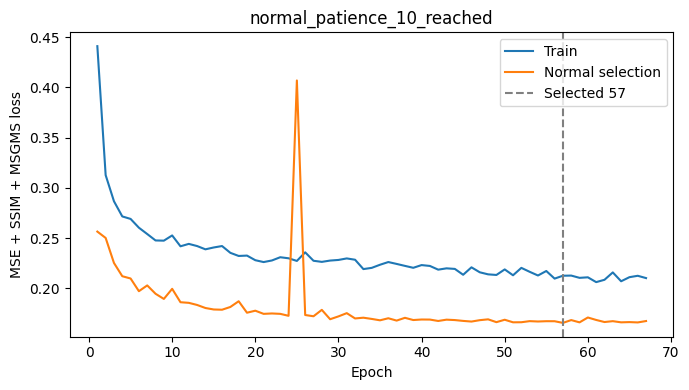

PosixPath('/kaggle/working/RIAD_baseline_6_100cap_report.zip')

In [5]:
def stopping_replay(hist):
    anchor=float('inf'); stale=0; stopped=None
    for row in hist:
        value=float(row['select_objective'])
        if not np.isfinite(value): raise RuntimeError('Nonfinite saved selection history.')
        if not np.isfinite(anchor) or value<anchor-max(STOP_ABS_FLOOR,abs(anchor)*STOP_MIN_RELATIVE):
            anchor=value; stale=0
        else: stale+=1
        if stale>=PATIENCE:
            stopped=int(row['epoch']); break
    return anchor,stale,stopped

def cpu_weights(net): return {k:v.detach().cpu().clone() for k,v in net.state_dict().items()}
def optimizer_to_device(opt):
    for item in opt.state.values():
        for k,v in item.items():
            if torch.is_tensor(v) and k!='step': item[k]=v.to(DEVICE)

def training_rng_state(mask_rng):
    return dict(python=random.getstate(),torch_cpu=torch.get_rng_state(),
                torch_cuda=torch.cuda.get_rng_state_all() if DEVICE.type=='cuda' else [],
                masks=mask_rng.bit_generator.state)

def restore_training_rng(state,mask_rng):
    random.setstate(state['python']);torch.set_rng_state(state['torch_cpu'])
    if DEVICE.type=='cuda':
        if len(state['torch_cuda'])!=torch.cuda.device_count():
            raise RuntimeError('CUDA RNG count changed. Resume on the same accelerator topology.')
        torch.cuda.set_rng_state_all(state['torch_cuda'])
    mask_rng.bit_generator.state=state['masks']

def audit_checkpoint_pair(last_state,selected_state,expected_config,maximum):
    if last_state.get('config_sha256')!=digest(expected_config) or selected_state.get('config_sha256')!=digest(expected_config):
        raise RuntimeError('Checkpoint configuration hash mismatch.')
    completed=int(last_state['epoch']);hist=list(last_state['history'])
    if not 0<=completed<=maximum or [int(h['epoch']) for h in hist]!=list(range(1,completed+1)):
        raise RuntimeError('Invalid completed-epoch history.')
    if not hist:
        if completed!=0 or int(selected_state['epoch'])!=0 or int(last_state['best_epoch'])!=0 or not np.isinf(float(last_state['best'])) or not np.isinf(float(selected_state['select_objective'])):
            raise RuntimeError('Invalid initial checkpoint placeholder.')
        return 0,0,float('inf'),hist
    vals=np.asarray([h['select_objective'] for h in hist],dtype=float)
    if not np.isfinite(vals).all():raise RuntimeError('Nonfinite checkpoint history.')
    best_epoch=int(np.argmin(vals))+1;best=float(vals[best_epoch-1])
    if int(selected_state['epoch'])!=best_epoch or int(last_state['best_epoch'])!=best_epoch:
        raise RuntimeError('best.pt does not match the absolute minimum normal-selection history.')
    if not np.isclose(best,float(last_state['best']),rtol=1e-7,atol=1e-10) or not np.isclose(best,float(selected_state['select_objective']),rtol=1e-7,atol=1e-10):
        raise RuntimeError('Saved checkpoint selection losses disagree.')
    return completed,best_epoch,best,hist

@torch.inference_mode()
def normal_validation():
    model.eval();totals=np.zeros(4);count=0;snapshot=evaluation_snapshot(model)
    for i,x in enumerate(batches(select_data)):
        budget_check(CHECKPOINT_RESERVE_SECONDS,'normal validation; saved training cursor will be resumed')
        x=x.to(DEVICE,non_blocking=True)*2-1
        y=inpaint(model,x,CUTOUTS[i%len(CUTOUTS)],np.random.default_rng(SEED+900000+i))
        values=objective(x,y);totals+=np.asarray([v.item() for v in values])*len(x);count+=len(x)
    assert_unchanged(snapshot,model)
    if not np.isfinite(totals).all():raise FloatingPointError('Validation diverged')
    return totals/count

optimizer=torch.optim.Adam(model.parameters(),lr=LR,weight_decay=WEIGHT_DECAY,
                           betas=(.9,.999),eps=1e-8,foreach=False)
completed=0;best_epoch=0;best=float('inf');history=[];stop_anchor=float('inf');stale=0
optimizer_steps=0;best_model=None;partial=None
if SOURCE_RUN is not None:
    state=load_pt(RUN/'last.pt');selected=load_pt(RUN/'best.pt')
    expected=source_config if MODE=='import_legacy100' else config
    # last.pt is the commit point and embeds the matching selected weights in new revisions.
    if 'best_model' in state and state['best_model'] is not None and int(selected['epoch'])!=int(state['best_epoch']):
        selected=dict(model=state['best_model'],epoch=int(state['best_epoch']),
            select_objective=float(state['best']),config_sha256=state['config_sha256'])
        save_pt(selected,RUN/'best.pt')
    completed,best_epoch,best,history=audit_checkpoint_pair(state,selected,expected,int(expected['epochs']))
    if completed>EPOCHS:raise RuntimeError('Legacy run already exceeds the new 100-epoch cap.')
    stop_anchor,stale,stopped=stopping_replay(history)
    if stopped is not None and stopped<completed:
        raise RuntimeError(f'The agreed early stopping would have stopped at epoch {stopped}; completed {completed}. Cannot relabel this trajectory. Use a fresh run.')
    model.load_state_dict(state['model'],strict=True)
    if 'optimizer' not in state:raise RuntimeError('last.pt lacks Adam state; exact continuation is impossible.')
    optimizer.load_state_dict(state['optimizer']);optimizer_to_device(optimizer)
    best_model={k:v.detach().cpu().clone() for k,v in selected['model'].items()}
    optimizer_steps=int(state.get('optimizer_steps',completed*((len(splits['train'])+BATCH-1)//BATCH)))
    partial=state.get('partial_epoch')
    if MODE=='import_legacy100':
        if completed<1:raise RuntimeError('Legacy import requires a committed validation epoch.')
        if partial is not None:raise RuntimeError('Legacy import accepts committed epoch checkpoints only.')
        # No trajectory-affecting field changed. Only cap, stopping and reporting policy change.
        write_json(RUN/'legacy_import.json',dict(source_run=str(SOURCE_RUN),
            source_last_sha256=sha(SOURCE_RUN/'last.pt'),source_best_sha256=sha(SOURCE_RUN/'best.pt'),
            source_config_sha256=digest(source_config),new_config_sha256=digest(config),
            source_epoch_cap=int(source_config['epochs']),completed_imported_epochs=completed,
            replay_stop_anchor=stop_anchor,replay_stale_epochs=stale,
            changed_fields=sorted(k for k in set(source_config)|set(config) if source_config.get(k)!=config.get(k)),
            justification='Constant LR, epoch seeds, loss, model, optimizer, data and preprocessing unchanged.'))
        # Publish the imported selected model under the new policy, with original SHA lineage above.
        save_pt(dict(model=best_model,epoch=best_epoch,select_objective=best,config_sha256=digest(config)),RUN/'best.pt')
    else:
        if state.get('stale_epochs')!=stale or not np.isclose(state.get('stop_anchor',stop_anchor),stop_anchor):
            raise RuntimeError('Stored early stopping counters disagree with completed history.')
        if partial is not None:
            if int(partial['epoch'])!=completed+1 or not 0<=int(partial['batch_cursor'])<=(len(splits['train'])+BATCH-1)//BATCH:
                raise RuntimeError('Invalid partial epoch cursor.')
    del state,selected
    print(f'Recovered {completed} completed epochs; selected {best_epoch}; stale {stale}; updates {optimizer_steps}')

def save_training_checkpoint(progress=None):
    # Atomic last.pt contains both current optimizer and selected weights; best.pt is repairable.
    save_pt(dict(model=model.state_dict(),optimizer=optimizer.state_dict(),epoch=completed,
        best=best,best_epoch=best_epoch,best_model=best_model,history=history,
        optimizer_steps=optimizer_steps,stale_epochs=stale,stop_anchor=stop_anchor,
        partial_epoch=progress,config_sha256=digest(config)),RUN/'last.pt')
    pd.DataFrame(history).to_csv(RUN/'training_history.csv',index=False)

if SOURCE_RUN is None:
    # This is explicitly an unselected initial placeholder, needed to resume an early session pause.
    best_model=cpu_weights(model)
    save_pt(dict(model=best_model,epoch=0,select_objective=float('inf'),
        config_sha256=digest(config),unselected_initial_placeholder=True),RUN/'best.pt')
    save_training_checkpoint()
if MODE=='import_legacy100':save_training_checkpoint()
paused=False
if MODE!='evaluate_completed':
    try:
        for epoch in range(completed+1,EPOCHS+1):
            if stale>=PATIENCE:break
            seed_all(SEED+epoch);model.train();mask_rng=np.random.default_rng(SEED+epoch)
            totals=np.zeros(4);count=0;cursor=0;previous_seconds=0.;begin=time.monotonic()
            if partial is not None:
                totals=np.asarray(partial['train_totals'],dtype=float);count=int(partial['train_count'])
                cursor=int(partial['batch_cursor']);previous_seconds=float(partial['elapsed_seconds'])
            def progress_snapshot():
                return dict(epoch=epoch,batch_cursor=cursor,train_totals=totals.tolist(),
                    train_count=count,elapsed_seconds=previous_seconds+time.monotonic()-begin,
                    rng=training_rng_state(mask_rng))
            loader=batches(train_data,True,epoch);iterator=iter(loader)
            for _ in range(cursor):next(iterator)
            if partial is not None:restore_training_rng(partial['rng'],mask_rng)
            partial=None
            for x in tqdm(iterator,total=len(loader)-cursor,desc=f'Train {epoch}, resume batch {cursor}'):
                if time.monotonic()+CHECKPOINT_RESERVE_SECONDS>=DEADLINE:
                    partial=progress_snapshot();save_training_checkpoint(partial)
                    raise SessionBudgetPause('training cursor saved before session budget')
                x=x.to(DEVICE,non_blocking=True)*2-1;optimizer.zero_grad(set_to_none=True)
                y=inpaint(model,x,random.choice(CUTOUTS),mask_rng);values=objective(x,y);loss=values[0]
                if not bool(torch.isfinite(loss)):raise FloatingPointError('Training diverged')
                loss.backward()
                if not bool(torch.stack([torch.isfinite(p.grad).all() for p in model.parameters() if p.grad is not None]).all()):
                    raise FloatingPointError('Nonfinite training gradients')
                optimizer.step();optimizer_steps+=1;cursor+=1
                totals+=np.asarray([v.item() for v in values])*len(x);count+=len(x)
                if cursor%SAVE_EVERY_BATCHES==0:
                    save_training_checkpoint(progress_snapshot())
            # Persist the fully trained partial epoch before fixed-mask validation.
            partial=progress_snapshot();save_training_checkpoint(partial)
            val=normal_validation();train=totals/count
            if val[0]<best:
                best=float(val[0]);best_epoch=epoch;best_model=cpu_weights(model)
            if not np.isfinite(stop_anchor) or val[0]<stop_anchor-max(STOP_ABS_FLOOR,abs(stop_anchor)*STOP_MIN_RELATIVE):
                stop_anchor=float(val[0]);stale=0
            else:stale+=1
            seconds=previous_seconds+time.monotonic()-begin;completed=epoch;partial=None
            row=dict(epoch=epoch,best_epoch=best_epoch,epoch_seconds=seconds,
                optimizer_steps=optimizer_steps,stale_epochs=stale,stop_anchor=stop_anchor)
            for j,name in enumerate(('objective','mse','ssim','msgms')):
                row['train_'+name]=float(train[j]);row['select_'+name]=float(val[j])
            history.append(row);save_training_checkpoint()
            if best_epoch==epoch:
                save_pt(dict(model=best_model,epoch=best_epoch,select_objective=best,
                    config_sha256=digest(config)),RUN/'best.pt')
            write_json(RUN/'status.json',dict(status='training',completed_epochs=completed,
                max_epochs=EPOCHS,selected_epoch=best_epoch,optimizer_steps=optimizer_steps,
                stale_epochs=stale,test_evaluated=False))
            print(f'Epoch {epoch}: train={train[0]:.6f}, select={val[0]:.6f}, best={best_epoch}, stale={stale}, seconds={seconds:.1f}',flush=True)
            report_zip()
    except SessionBudgetPause as exc:
        paused=True
        # Validation pauses leave a complete training cursor in last.pt. Training pauses saved above.
        print('Safely paused:',exc)
    except BaseException:
        report_zip();raise

training_complete=completed>=EPOCHS or stale>=PATIENCE
training_status='maximum_100_epochs_reached' if completed>=EPOCHS else ('normal_patience_10_reached' if stale>=PATIENCE else 'paused_for_resume')
if MODE=='evaluate_completed' and not training_complete:
    raise RuntimeError('Evaluation requires completed 100-cap policy or normal-only early stopping. Resume training first.')
EVALUATE=training_complete and not paused
write_json(RUN/'status.json',dict(status=training_status,completed_epochs=completed,max_epochs=EPOCHS,
    selected_epoch=best_epoch,optimizer_steps=optimizer_steps,stale_epochs=stale,
    partial_epoch_number=(partial or {}).get('epoch'),partial_batch_cursor=(partial or {}).get('batch_cursor'),
    test_evaluated=False,next_action=('Evaluate the locked model.' if EVALUATE else 'Attach this full output and use MODE=resume100.')))
if EVALUATE:
    selected=load_pt(RUN/'best.pt');model.load_state_dict(selected['model'],strict=True);model.eval()
    if selected.get('config_sha256')!=digest(config):raise RuntimeError('Selected configuration changed.')
    del selected
    write_json(RUN/'selected_checkpoint.json',dict(epoch=best_epoch,select_objective=best,
        sha256=sha(RUN/'best.pt'),trained_epochs=completed,max_epochs=EPOCHS,
        optimizer_steps=optimizer_steps,training_status=training_status,
        checkpoint_selection='absolute minimum fixed-mask normal selection objective'))
else:print('No test evaluation: the training policy is not complete.')
if history:
    h=pd.DataFrame(history);fig,ax=plt.subplots(figsize=(7,4))
    ax.plot(h.epoch,h.train_objective,label='Train');ax.plot(h.epoch,h.select_objective,label='Normal selection')
    ax.axvline(best_epoch,ls='--',color='gray',label=f'Selected {best_epoch}')
    ax.set(xlabel='Epoch',ylabel='MSE + SSIM + MSGMS loss',title=training_status)
    ax.legend();fig.tight_layout();fig.savefig(RUN/'training_curve.png',dpi=150);plt.show()
write_json(RUN/'training_budget.json',dict(maximum_epochs=EPOCHS,completed_epochs=completed,
    selected_epoch=best_epoch,optimizer_steps=optimizer_steps,batch_size=BATCH,
    training_frames=len(splits['train']),updates_per_complete_epoch=(len(splits['train'])+BATCH-1)//BATCH,
    early_stopping_patience=PATIENCE,early_stopping_min_relative=STOP_MIN_RELATIVE,
    early_stopping_absolute_floor=STOP_ABS_FLOOR,training_status=training_status,
    validation_every_epochs=1,trainable_parameters=PARAMETERS,total_parameters=PARAMETERS,
    pretrained_parameters=0,used_gpus=1,
    committed_epoch_seconds=float(sum(r['epoch_seconds'] for r in history))))
del optimizer,best_model
report_zip()


## 4. Lock normal thresholds and resume score maps
Checkpoint SHA plus configuration SHA identify score caches. Thresholds are locked before test
masks are decoded. A scoring pause saves completed map rows so the next evaluation session can resume.

In [6]:
STRUCT=generate_binary_structure(2,2)
def postprocess(mask):
    m=binary_closing(mask,structure=STRUCT,iterations=2)
    m=binary_opening(m,structure=STRUCT,iterations=1); m=binary_fill_holes(m)
    cc,_=label(m); keep=np.bincount(cc.ravel())>=50; keep[0]=False
    return binary_opening(keep[cc],structure=STRUCT,iterations=2)
# A new cache namespace separates these incrementally committed maps from old all-or-nothing maps.
MAP_DIR=CACHE/('recovery_scores_'+sha(RUN/'best.pt')[:16])
SOURCE_MAP_DIR=SOURCE_RUN/'_cache'/MAP_DIR.name if SOURCE_RUN is not None else None
if not MAP_DIR.exists() and SOURCE_MAP_DIR is not None and SOURCE_MAP_DIR.is_dir() and SOURCE_MAP_DIR.resolve()!=MAP_DIR.resolve():
    print('Recovering saved scoring progress from:',SOURCE_MAP_DIR)
    shutil.copytree(SOURCE_MAP_DIR,MAP_DIR)
MAP_DIR.mkdir(exist_ok=True)

def score_maps(role):
    model.eval(); snapshot=evaluation_snapshot(model)
    paths={s:MAP_DIR/f'{s}_{role}.npy' for s in SCORES}
    progress=MAP_DIR/f'{role}_progress.json'
    shape=(len(splits[role]),SIZE,SIZE)
    if progress.exists():
        stamp=json.loads(progress.read_text())
        if stamp['config_sha256']!=digest(config) or stamp['checkpoint_sha256']!=sha(RUN/'best.pt'):
            raise RuntimeError('Foreign score cache.')
        done=int(stamp['completed_frames'])
        if not 0<=done<=shape[0]: raise RuntimeError('Invalid score-cache index.')
        if not all(p.is_file() for p in paths.values()): raise RuntimeError('Missing partial score maps.')
        arr={s:np.load(p,mmap_mode='r+') for s,p in paths.items()}
        for a in arr.values():
            if a.shape!=shape or a.dtype!=np.float32: raise RuntimeError('Invalid score map shape/dtype.')
    else:
        done=0
        arr={s:np.lib.format.open_memmap(p,mode='w+',dtype=np.float32,shape=shape) for s,p in paths.items()}
    checkpoint_hash=sha(RUN/'best.pt')
    def commit(n):
        for a in arr.values():a.flush()
        write_json(progress,dict(completed_frames=n,total_frames=shape[0],
            checkpoint_sha256=checkpoint_hash,config_sha256=digest(config)))
    commit(done)
    if done<shape[0]:
        data=cache_images(role)
        start=time.monotonic();first=done;frame_seconds=1.0
        try:
            for i in tqdm(range(done,len(data)),desc=f'Reconstruct {role} (resume {done})'):
                budget_check(max(120,3*frame_seconds),'scoring '+role)
                before=time.monotonic();_,raw=inference_maps(model,data[i])
                frame_seconds=max(frame_seconds,time.monotonic()-before)
                for s in SCORES:
                    if not np.isfinite(raw[s]).all(): raise FloatingPointError('Invalid '+s)
                    arr[s][i]=raw[s]
                done=i+1
                if done%SCORE_FLUSH_EVERY==0 or done==len(data): commit(done)
                if done-first==8:
                    mean=(time.monotonic()-start)/(done-first)
                    print(f'{role}: {mean:.2f}s/frame; remaining in this split ~{mean*(len(data)-done)/60:.1f} min',flush=True)
        finally:
            # Even a Python interruption keeps fully written frames. Hard kills lose at most a flush interval.
            commit(done)
            assert_unchanged(snapshot,model)
    result={s:np.load(p,mmap_mode='r') for s,p in paths.items()}
    for a in result.values():
        for frame in a:
            if not np.isfinite(frame).all(): raise FloatingPointError('Invalid cached scores')
    assert_unchanged(snapshot,model)
    return result

if EVALUATE:
    try:
        maps={role:score_maps(role) for role in ('select','calibrate','audit')}
        thresholds={}; audit_rows=[]
        for s in SCORES:
            vals=np.concatenate([maps[r][s].ravel() for r in ('select','calibrate','audit')])
            q1,q3=np.percentile(vals,[25,75]); thresholds[s]={'historical':float(q3+4*(q3-q1))}; del vals
            rng=np.random.default_rng(SEED+71)
            sample=np.concatenate([a.ravel()[rng.choice(SIZE*SIZE,4096,replace=False)] for a in maps['calibrate'][s]])
            for f in FPRS: thresholds[s][f'fpr_{f:g}']=float(np.quantile(sample,1-f,method='higher'))
            for protocol,t in thresholds[s].items():
                raw=[]; post=[]
                for a in maps['audit'][s]:
                    pred=a>t; raw.append(float(pred.mean())); post.append(float(postprocess(pred).mean()))
                audit_rows.append(dict(score=s,protocol=protocol,threshold=t,audit_raw_fpr=float(np.mean(raw)),audit_post_fpr=float(np.mean(post)),audit_used_in_threshold=(protocol=='historical')))
        write_json(RUN/'thresholds_LOCKED.json',thresholds)
        write_json(RUN/'evaluation_lock.json',dict(checkpoint_sha256=sha(RUN/'best.pt'),
            config_sha256=digest(config),thresholds_sha256=digest(thresholds),
            selected_epoch=best_epoch,trained_epochs=completed,training_status=training_status,
            model_selection='normal selection only',test_labels_used_for_selection=False))
        audit=pd.DataFrame(audit_rows); audit.to_csv(RUN/'normal_fpr.csv',index=False)
        print('Model and thresholds locked before test masks are decoded.')
        display(audit)
    except SessionBudgetPause as exc:
        EVALUATE=False
        print('PAUSED safely:',exc)
        print('Keep this full output; attach it to the same notebook in a new session.')
        display(FileLink(str(report_zip())))
else:
    print('Evaluation skipped: training-only mode or an earlier safe pause.')


Reconstruct select (resume 0):   0%|          | 0/521 [00:00<?, ?it/s]

select: 0.47s/frame; remaining in this split ~4.0 min


Resize calibrate:   0%|          | 0/128 [00:00<?, ?it/s]

Reconstruct calibrate (resume 0):   0%|          | 0/128 [00:00<?, ?it/s]

calibrate: 0.47s/frame; remaining in this split ~0.9 min


Resize audit:   0%|          | 0/234 [00:00<?, ?it/s]

Reconstruct audit (resume 0):   0%|          | 0/234 [00:00<?, ?it/s]

audit: 0.46s/frame; remaining in this split ~1.7 min
Model and thresholds locked before test masks are decoded.


,score,protocol,threshold,audit_raw_fpr,audit_post_fpr,audit_used_in_threshold
0,shared_mae,historical,0.030503,0.176284,0.199596,True
1,shared_mae,fpr_0.005,0.121571,0.006725,0.001344,False
2,shared_mae,fpr_0.01,0.099850,0.013559,0.004691,False
3,shared_mae,fpr_0.02,0.080157,0.026971,0.015642,False
4,shared_mae,fpr_0.05,0.055750,0.067839,0.065705,False
5,shared_mae,fpr_0.1,0.037458,0.137439,0.157474,False
6,riad_msgms,historical,0.876780,0.000030,0.000024,True
7,riad_msgms,fpr_0.005,0.559492,0.005330,0.004824,False
8,riad_msgms,fpr_0.01,0.524541,0.011374,0.010531,False
9,riad_msgms,fpr_0.02,0.486746,0.024281,0.023159,False


## 5. Foreground IoU and supporting metrics
`headline_metrics.csv` reports historical postprocessed mean foreground frame IoU for both scores.
`summary.csv` also reports the independent normal-calibrated FPR 0.02 protocol and its audit FPR.
Pixel AP/AUROC/AUPRO use the full continuous maps before morphology; AUPRO integrates FPR through 0.30
with equal weight per 8-connected ground-truth region. Image AP/AUROC are undefined if this test set
contains only anomalous images, and are explicitly recorded as missing rather than invented.

In [7]:
def pixel_ranking(scores, masks):
    # Exact AP/AUROC, with tied scores grouped, using a single sorting pass.
    # PRO gives every 8-connected GT region equal weight, integrates FPR<=0.30,
    # and normalizes by 0.30. Test labels here calculate metrics, not thresholds.
    y = np.asarray(masks, dtype=np.bool_).ravel()
    score = np.asarray(scores, dtype=np.float32).ravel()
    positives, negatives = int(y.sum()), int((~y).sum())
    if positives == 0 or negatives == 0:
        return dict(pixel_ap=None, pixel_auroc=None, pixel_aupro_0p30=None,
                    gt_regions=0, positive_pixels=positives, negative_pixels=negatives)
    weights = np.zeros(masks.shape, dtype=np.float32)
    regions = 0
    for i, m in enumerate(masks):
        cc, n = label(m, structure=STRUCT)
        areas = np.bincount(cc.ravel())
        lookup = np.zeros(len(areas), dtype=np.float32)
        lookup[1:] = 1. / areas[1:]
        weights[i] = lookup[cc]
        regions += n
    order = np.argsort(score, kind='stable')[::-1]
    sorted_scores = score[order]
    ends = np.r_[np.flatnonzero(np.diff(sorted_scores)), len(score) - 1]
    del sorted_scores
    cumsum = np.cumsum(y[order], dtype=np.int64)
    tp = cumsum[ends].astype(np.float64)
    del cumsum
    fp = (ends + 1).astype(np.float64) - tp
    ap = float(np.sum(np.diff(np.r_[0., tp]) * (tp / (ends + 1))) / positives)
    fpr = np.r_[0., fp / negatives]
    tpr = np.r_[0., tp / positives]
    trapz = getattr(np, 'trapezoid', None) or np.trapz
    auroc = float(trapz(tpr, fpr))
    del tp, fp, tpr
    region_cumsum = np.cumsum(weights.ravel()[order], dtype=np.float64)
    pro = np.r_[0., region_cumsum[ends] / regions]
    del region_cumsum, weights, order, ends
    cap = .30
    # Keep all vertical segments at a repeated FPR; interpolate the crossing segment.
    right = int(np.searchsorted(fpr, cap, side='right'))
    xx, yy = fpr[:right], pro[:right]
    if xx[-1] < cap:
        upper = right
        endpoint = yy[-1] + (pro[upper] - yy[-1]) * (cap - xx[-1]) / (fpr[upper] - xx[-1])
        xx = np.r_[xx, cap]
        yy = np.r_[yy, endpoint]
    aupro = float(trapz(yy, xx) / cap)
    return dict(pixel_ap=ap, pixel_auroc=auroc, pixel_aupro_0p30=aupro,
                gt_regions=int(regions), positive_pixels=positives, negative_pixels=negatives)

if EVALUATE:
    try:
        lock=json.loads((RUN/'evaluation_lock.json').read_text())
        assert lock['checkpoint_sha256']==sha(RUN/'best.pt')
        assert lock['thresholds_sha256']==digest(thresholds)
        maps['test']=score_maps('test')
        budget_check(900, 'time reserved for metrics')
        gt=np.lib.format.open_memmap(CACHE/'test_masks.npy',mode='w+',dtype=np.bool_,shape=(len(splits['test']),SIZE,SIZE))
        mask_hashes=[]
        for i,r in enumerate(tqdm(splits['test'],desc='Read locked test masks')):
            with Image.open(r['mask']) as im:
                gt[i]=np.asarray(im.convert('L').resize((SIZE,SIZE),Image.Resampling.BILINEAR),dtype=np.float32)/255>.5
            mask_hashes.append(dict(relative=r['relative'],sha256=sha(r['mask'])))
        gt.flush(); assert gt.any() and not gt.all()
        write_json(RUN/'mask_hashes.json',mask_hashes)
        def confusion(pred,target):
            return (int(np.count_nonzero(pred&target)),int(np.count_nonzero(pred&~target)),int(np.count_nonzero(~pred&target)),int(np.count_nonzero(~pred&~target)))
        def iou(tp,fp,fn): return tp/(tp+fp+fn) if tp+fp+fn else 1.0
        rows=[]
        for s in SCORES:
            for protocol,t in tqdm(thresholds[s].items(),desc='Evaluate '+s):
                for i,r in enumerate(splits['test']):
                    raw=maps['test'][s][i]>t
                    for processing,pred in [('raw',raw),('postprocessed',postprocess(raw))]:
                        tp,fp,fn,tn=confusion(pred,gt[i])
                        rows.append(dict(score=s,protocol=protocol,processing=processing,relative=r['relative'],video=r['video'],tp=tp,fp=fp,fn=fn,tn=tn,iou=iou(tp,fp,fn),dice=(2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else 1.0),frame_precision=(tp/(tp+fp) if tp+fp else 0.),frame_recall=(tp/(tp+fn) if tp+fn else 0.)))
        frames=pd.DataFrame(rows); frames.to_csv(RUN/'test_frame_metrics.csv',index=False)
        keys=['score','protocol','processing']; summary_rows=[]
        for (s,protocol,processing),group in frames.groupby(keys,sort=False):
            tp,fp,fn,tn=[int(group[c].sum()) for c in ('tp','fp','fn','tn')]
            a=audit[(audit.score==s)&(audit.protocol==protocol)].iloc[0]
            summary_rows.append(dict(score=s,protocol=protocol,processing=processing,mean_frame_iou=float(group.iou.mean()),mean_iou=float(group.iou.mean()),mean_frame_dice=float(group.dice.mean()),mean_frame_precision=float(group.frame_precision.mean()),mean_frame_recall=float(group.frame_recall.mean()),pooled_dice=(2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else 1.0),max_epochs=EPOCHS,optimizer_steps=optimizer_steps,trainable_parameters=PARAMETERS,total_parameters=PARAMETERS,pretrained_parameters=0,selected_epoch=best_epoch,trained_epochs=completed,training_status=training_status,threshold=float(thresholds[s][protocol]),pooled_iou=iou(tp,fp,fn),pooled_precision=tp/(tp+fp) if tp+fp else 0.,pooled_recall=tp/(tp+fn) if tp+fn else 0.,audit_raw_fpr=float(a.audit_raw_fpr),audit_post_fpr=float(a.audit_post_fpr)))
        summary=pd.DataFrame(summary_rows); summary.to_csv(RUN/'summary.csv',index=False)
        headline=summary[(summary.protocol=='historical')&(summary.processing=='postprocessed')]
        headline.to_csv(RUN/'headline_metrics.csv',index=False)
        frames.groupby(keys+['video'],as_index=False).agg(mean_frame_iou=('iou','mean'),frames=('iou','size')).to_csv(RUN/'test_video_metrics.csv',index=False)
        # Exact full-pixel metrics: CPU/RAM intensive, computed sequentially.
        ranking=[]
        ranking_path=RUN/'full_pixel_ranking.csv'
        # Recompute rankings for the currently locked checkpoint; never inherit stale CSV rows.
        for s in SCORES:
            if any(row['score']==s for row in ranking): continue
            budget_check(900, 'time reserved for exact full-pixel metrics')
            print('Full-pixel AP/AUROC:',s,flush=True)
            image_labels=np.asarray(gt).reshape(len(gt),-1).any(1)
            image_scores=np.asarray(maps['test'][s]).reshape(len(gt),-1).max(1)
            image_metrics=dict(image_ap=None,image_auroc=None,image_score='maximum pixel score',
                image_metric_status='undefined: test set contains one image class')
            if len(np.unique(image_labels))==2:
                image_metrics.update(image_ap=float(average_precision_score(image_labels,image_scores)),
                    image_auroc=float(roc_auc_score(image_labels,image_scores)),image_metric_status='defined')
            ranking.append(dict(score=s,**pixel_ranking(maps['test'][s],gt),**image_metrics,
                selected_epoch=best_epoch,trained_epochs=completed,max_epochs=EPOCHS,
                optimizer_steps=optimizer_steps,training_status=training_status))
            pd.DataFrame(ranking).to_csv(ranking_path,index=False)
        pd.DataFrame(ranking).to_csv(RUN/'full_pixel_ranking.csv',index=False)
        print('Historical comparison — use mean_frame_iou, postprocessed:')
        display(summary[(summary.protocol=='historical')&(summary.processing=='postprocessed')])
        print('Normal calibration target FPR 0.02:')
        display(summary[(summary.protocol=='fpr_0.02')&(summary.processing=='postprocessed')])
        display(pd.DataFrame(ranking))
    except SessionBudgetPause as exc:
        EVALUATE=False
        print('PAUSED safely:',exc)
        print('Keep this full output; attach it to the same notebook in a new session.')
        display(FileLink(str(report_zip())))
else:
    print('Evaluation skipped: training-only mode or an earlier safe pause.')


Resize test:   0%|          | 0/496 [00:00<?, ?it/s]

Reconstruct test (resume 0):   0%|          | 0/496 [00:00<?, ?it/s]

test: 0.47s/frame; remaining in this split ~3.8 min


Read locked test masks:   0%|          | 0/496 [00:00<?, ?it/s]

Evaluate shared_mae:   0%|          | 0/6 [00:00<?, ?it/s]

...

Full-pixel AP/AUROC: shared_mae
Full-pixel AP/AUROC: riad_msgms
Historical comparison — use mean_frame_iou, postprocessed:


,score,protocol,processing,mean_frame_iou,mean_iou,mean_frame_dice,mean_frame_precision,mean_frame_recall,pooled_dice,max_epochs,...,pretrained_parameters,selected_epoch,trained_epochs,training_status,threshold,pooled_iou,pooled_precision,pooled_recall,audit_raw_fpr,audit_post_fpr
1,shared_mae,historical,postprocessed,0.330757,0.330757,0.487768,0.356492,0.834419,0.502082,100,...,0,57,67,normal_patience_10_reached,0.030503,0.335187,0.358990,0.834849,0.176284,0.199596
13,riad_msgms,historical,postprocessed,0.000164,0.000164,0.000322,0.012709,0.000164,0.000338,100,...,0,57,67,normal_patience_10_reached,0.876780,0.000169,0.649593,0.000169,0.000030,0.000024


Normal calibration target FPR 0.02:


,score,protocol,processing,mean_frame_iou,mean_iou,mean_frame_dice,mean_frame_precision,mean_frame_recall,pooled_dice,max_epochs,...,pretrained_parameters,selected_epoch,trained_epochs,training_status,threshold,pooled_iou,pooled_precision,pooled_recall,audit_raw_fpr,audit_post_fpr
7,shared_mae,fpr_0.02,postprocessed,0.14575,0.14575,0.249275,0.525149,0.169756,0.251665,100,...,0,57,67,normal_patience_10_reached,0.080157,0.143945,0.536195,0.164417,0.026971,0.015642
19,riad_msgms,fpr_0.02,postprocessed,0.06535,0.06535,0.119528,0.225811,0.088136,0.126082,100,...,0,57,67,normal_patience_10_reached,0.486746,0.067283,0.214169,0.089338,0.024281,0.023159


,score,pixel_ap,pixel_auroc,pixel_aupro_0p30,gt_regions,positive_pixels,negative_pixels,image_ap,image_auroc,image_score,image_metric_status,selected_epoch,trained_epochs,max_epochs,optimizer_steps,training_status
0,shared_mae,0.410115,0.847258,0.559453,3688,4732744,27773112,None,None,maximum pixel score,undefined: test set contains one image class,57,67,100,64186,normal_patience_10_reached
1,riad_msgms,0.254003,0.758348,0.267619,3688,4732744,27773112,None,None,maximum pixel score,undefined: test set contains one image class,57,67,100,64186,normal_patience_10_reached


## 6. Fixed examples and compact report
The examples use fixed manifest indices. Retain both score rows even if one performs worse.
Preserve the previous exploratory result separately; this new policy does not overwrite it.

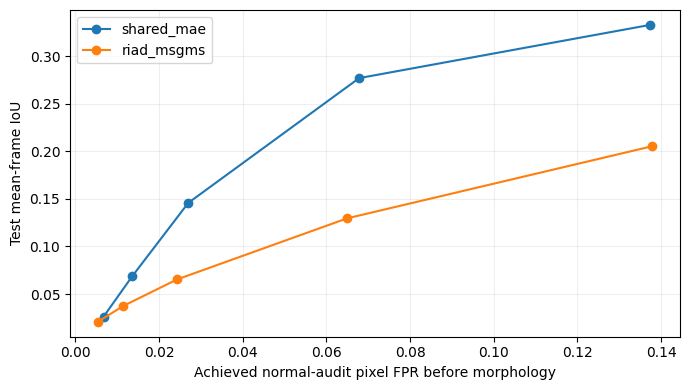

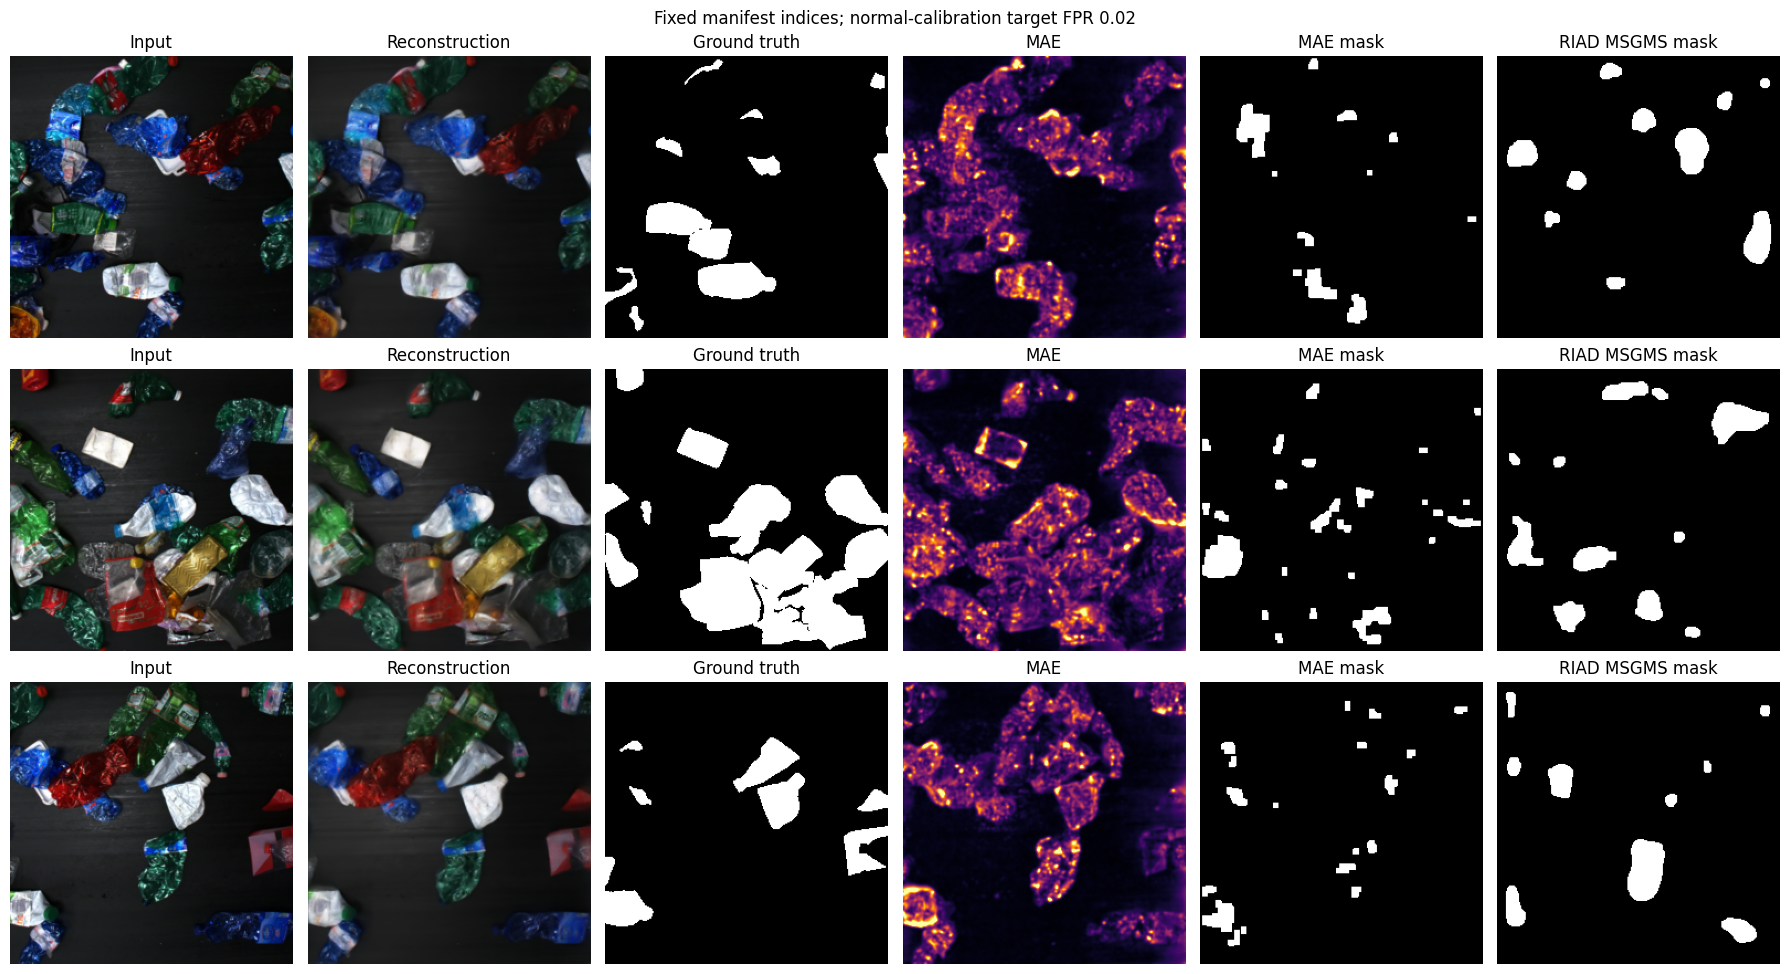

Evaluation complete. Training status: normal_patience_10_reached
Main RGB-error historical result:


,score,protocol,processing,mean_frame_iou,mean_iou,mean_frame_dice,mean_frame_precision,mean_frame_recall,pooled_dice,max_epochs,...,pretrained_parameters,selected_epoch,trained_epochs,training_status,threshold,pooled_iou,pooled_precision,pooled_recall,audit_raw_fpr,audit_post_fpr
1,shared_mae,historical,postprocessed,0.330757,0.330757,0.487768,0.356492,0.834419,0.502082,100,...,0,57,67,normal_patience_10_reached,0.030503,0.335187,0.35899,0.834849,0.176284,0.199596


Send this compact report and the notebook log:


/kaggle/working/RIAD_baseline_6_100cap_report.zip

Retain best.pt, last.pt and the full output in /kaggle/working/RIAD_baseline_6_100cap


In [8]:
if EVALUATE:
    try:
        fig,ax=plt.subplots(figsize=(7,4))
        for s in SCORES:
            d=summary[(summary.score==s)&(summary.processing=='postprocessed')&(summary.protocol!='historical')].sort_values('audit_raw_fpr')
            ax.plot(d.audit_raw_fpr,d.mean_frame_iou,'o-',label=s)
        ax.set(xlabel='Achieved normal-audit pixel FPR before morphology',ylabel='Test mean-frame IoU'); ax.legend(); ax.grid(alpha=.2)
        fig.tight_layout(); fig.savefig(RUN/'iou_vs_fpr.png',dpi=150); plt.show()
        indices=np.linspace(0,len(splits['test'])-1,3,dtype=int); data=cache_images('test')
        fig,axes=plt.subplots(3,6,figsize=(18,10))
        for row,i in enumerate(indices):
            rec=reconstruct(model,data[i]); t=thresholds['shared_mae']['fpr_0.02']; t2=thresholds['riad_msgms']['fpr_0.02']
            panels=[(data[i],'Input',None),(np.clip(rec,0,1),'Reconstruction',None),(gt[i],'Ground truth','gray'),(maps['test']['shared_mae'][i],'MAE','inferno'),(postprocess(maps['test']['shared_mae'][i]>t),'MAE mask','gray'),(postprocess(maps['test']['riad_msgms'][i]>t2),'RIAD MSGMS mask','gray')]
            for col,(a,title,cmap) in enumerate(panels):
                if col==3: axes[row,col].imshow(a,cmap=cmap,vmin=0,vmax=max(2*t,1e-8))
                else: axes[row,col].imshow(a,cmap=cmap)
                axes[row,col].set_title(title); axes[row,col].axis('off')
        fig.suptitle('Fixed manifest indices; normal-calibration target FPR 0.02')
        fig.tight_layout(); fig.savefig(RUN/'fixed_examples.png',dpi=150); plt.show()
        write_json(RUN/'fixed_examples.json',[splits['test'][int(i)]['relative'] for i in indices])

        write_json(RUN/'status.json',dict(status='evaluation_complete',mode=MODE,trained_epochs=completed,
            max_epochs=EPOCHS,optimizer_steps=optimizer_steps,training_status=training_status,parameters=PARAMETERS,selected_epoch=best_epoch,
            selection_objective=best,elapsed_hours=(time.monotonic()-SESSION_START)/3600))
        print('Evaluation complete. Training status:',training_status)
        print('Main RGB-error historical result:')
        display(summary[(summary.score=='shared_mae')&(summary.protocol=='historical')&(summary.processing=='postprocessed')])
    except SessionBudgetPause as exc:
        EVALUATE=False
        print('PAUSED safely:',exc)
        print('Keep this full output; attach it to the same notebook in a new session.')
        display(FileLink(str(report_zip())))
else:
    print('Evaluation skipped: training-only mode or an earlier safe pause.')

# This runs in evaluation, continuation and safe-pause modes.
try:
    (RUN/'executed_cells.py').write_text('\n\n'.join(get_ipython().history_manager.input_hist_raw))
except NameError: pass
report=report_zip()
print('Send this compact report and the notebook log:')
display(FileLink(str(report)))
print('Retain best.pt, last.pt and the full output in',RUN)
